<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_CyberAttackDetection_Moll2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC for cyber-attack detection: Moll and Kunczik (2025) step by step

This notebook re-implements, runs and checks the method of

> Maximilian Moll and Leonhard Kunczik, "A case study for cyber-attack detection using quantum variational circuits",
> *Quantum Machine Intelligence* (2025). DOI [10.1007/s42484-025-00277-1](https://doi.org/10.1007/s42484-025-00277-1)
> (preprint: Research Square, DOI 10.21203/rs.3.rs-2421990/v1, 6 January 2023).

The paper publishes no code ("available on request"). Everything below is written from the paper's text, Tables 1 to 3 and the appendix.
The numbers quoted as "the paper" are those of the **preprint** that sits in the repository; the published version may differ in detail.

**What the paper does.** It classifies network flows of the IoT-23 data set as benign or malicious with a *hybrid* model: a dense layer
turns the flow features into rotation angles, a quantum variational circuit (QVC, also called parameterised quantum circuit) processes
them, and a dense layer with a sigmoid makes the decision. Its new idea, **vertical layers**, puts several small QVCs side by side
(each with its own dense encoder) instead of one big circuit, so that each circuit needs fewer qubits and layers and could run on a
separate small quantum computer. It compares single QVCs (1 to 11 qubits, up to 7 layers), vertical stacks, feature reduction and a classical DNN.

**What this notebook does.** It downloads the same kind of data (IoT-23 Zeek flow records, binary benign/malicious labels), builds the
hybrid model gate by gate (exact state-vector simulation in PyTorch, cross-checked against a PennyLane QNode that is also drawn),
verifies that the layout reproduces the **exact parameter counts of 15 of the 16 models** printed in the paper, trains the single QVCs, the four
vertical models of Table 2, the reduced-data models of Table 3 and the classical DNN, adds a no-quantum control, and puts the measured
numbers next to the paper's with a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo on 1,000 training
flows; `FAST_MODE = False` uses a larger grid, 2,000 training flows, a 2,000-flow test split and three seeds (budgets in the configuration cell). No GPU, IBM
account or Hugging Face token is needed (the three data mirrors are public); a gated mirror would need your own token in Colab *Secrets*
(`HF_TOKEN`), which the data cell reads from there or from the environment and never prints.

**What you get at the end.** The paper-versus-notebook table, dataset plots with ground-truth labels, drawings of the circuits that
were actually trained, and a critical reading of what the paper can and cannot claim.

> **Honest scale warning.** The paper trains on the whole IoT-23 table (hundreds of thousands of flows) for 10 epochs, i.e. tens of
> thousands of optimiser steps per model. A CPU simulator cannot do that for 9-qubit circuits in a class notebook, so here every model sees
> a few hundred to two thousand flows (a few hundred optimiser steps). Absolute accuracies are therefore expected to be lower than the paper's;
> the comparisons *between* models under an identical budget are what this notebook can check.

## The paper in one page

**Problem.** Decide for each IoT network flow whether it is malicious (binary). The paper uses the data set as a vehicle to study how
variational quantum models scale to "big data" with small NISQ machines.

**Data (Section 1, Section 4).** IoT-23 (Garcia et al.), labelled flows from IoT devices. The full set has **11 features**. A second,
**reduced** set is built in Section 4.3: duplicates are removed, the majority class is undersampled to balance the classes, and the
three features with Spearman correlation below 0.01 to the label are dropped (**8 features**; the paper names `duration`, `obytes`, `iipbytes`).

**Model (Section 3).** `f(x) = psi( f_theta1(phi_1(x)), ..., f_thetam(phi_m(x)) )`:
a dense layer `phi_i` maps the features to as many angles as the block has qubits; a QVC with `L` *horizontal layers* (data encoding
repeated in each layer, RY rotations as in Fig. 1) returns one expectation value per qubit; one shared dense layer `psi` with a sigmoid
combines the blocks. `m = 1` is the plain baseline, `m > 1` are the **vertical layers**. All models: Adam, 10 epochs, binary cross-entropy.

**Experiments and claims (Section 4, Tables 1 to 3 and A1 to A9).**
1. Baseline QVCs, 1 to 11 qubits x 1 to `max(q, 7)` layers, learning rates 0.001, 0.01, 0.1, 0.2 (56 cells per rate). Best: 9 qubits,
   6 layers, 217 parameters, accuracy **0.9893**. The best classical DNN (Optuna, 200 trials; 2 hidden layers of 40 and 38 sigmoid units, 2,077
   parameters) reaches **0.9931**, so the gap is below 0.4 points with about 6x fewer parameters for the QVC (as the paper words it).
2. Vertical models found with Optuna (up to 5 blocks of up to 7 qubits, 2 to 4 layers): best accuracy **0.9889** (lr 0.1, 293 parameters)
   and **0.9882** (lr 0.2, 295 parameters), only about 0.04 points below the baseline; lr 0.001 is clearly worse (0.9642).
3. Reduced data (8 features): single QVCs reach at best **0.9874** (7 qubits, 6 layers, 148 parameters), 0.19 points below the full-data baseline;
   the DNN reaches **0.9937** (23 and 40 units, 1,208 parameters). The paper concludes that vertical layers cut the circuit size
   *without* needing feature reduction, which costs a little accuracy.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | not stated (Adam, Optuna mentioned) | exact state-vector simulator in PyTorch (autograd gives exact gradients; the paper's parameter-shift rule gives the same values on a noiseless device); every circuit is cross-checked against a PennyLane QNode, which is also what is drawn |
| Data | IoT-23, "11 features", 10 epochs on the full table | Hugging Face mirror `19kmunz/iot-23-preprocessed` (819,024 Zeek conn.log flows, **binary** label Malicious/Benign, from the Kaggle subset of 6 M flows); a **random sample** of 1,000 + 1,000 flows (FAST) or 2,000 + 2,000 (full run) is used |
| The 11 features | not listed | `# CHOICE:` `id.resp_p, proto, conn_state, duration, orig_bytes, resp_bytes, missed_bytes, orig_pkts, orig_ip_bytes, resp_pkts, resp_ip_bytes` (the paper's three dropped names suggest byte-count columns of this kind) |
| Encoding of raw columns | not stated | `# CHOICE:` category -> ordinal code, missing values -> 0, signed `log1p`, standardise (train split only), clip to +-5 |
| Full data class mix | not stated | natural mix (about 66 % malicious) |
| Reduced data | drop duplicates, undersample majority class, drop 3 features with Spearman < 0.01 | drop duplicates (819,024 -> 72,810 flows), balanced sample, drop the **3 weakest** features by Spearman on the training split (here no feature is below 0.01, so the strict rule would drop none) |
| Split | not stated | `# CHOICE:` stratified train / test; 15 % of train held out as validation to pick configurations (never the test split) |
| Circuit layout | RY encoding repeated per layer (Fig. 1 / eq. 3); trainable gates and entanglers not given | `# CHOICE:` per layer RY(phi) on every qubit, trainable RX, CNOT ring, trainable RZ (RZ omitted after the last layer). This layout gives `q(2L-1)` circuit angles and reproduces 15 of the 16 printed parameter counts exactly |
| Encoder `phi_i` | "a single fully-connected NN layer" | `Linear(features -> q)`, no activation (the parameter counts require this) |
| Read-out `psi` | dense layer + sigmoid | `Linear(sum of qubits -> 1)` on the `<Z_i>` of all qubits, sigmoid inside the BCE loss |
| Optimiser | Adam, 10 epochs, lrs 0.001 / 0.01 / 0.1 / 0.2, batch size not given | Adam, 10 epochs, the same learning rates; `# CHOICE:` batch 64, circuit angles initialised N(0, 0.5^2), PyTorch default for dense layers |
| Search | full grid 56 cells x 4 lrs; Optuna 200 + 4 x 90 trials | a sub-grid (configuration cell); the four Table 2 vertical architectures and the Table 1 / 3 DNN architectures are **taken from the paper**, not searched |
| Metrics | accuracy, precision, recall, F1 (precision ~ accuracy, so macro averages) | the same, macro-averaged; confusion matrices with malicious as the positive class |
| Classical references | Optuna-tuned DNN, sigmoid units | the paper's DNN architectures; plus RandomForest and SVC(rbf) on the identical inputs, and a no-quantum control (dense + tanh bottleneck) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("pennylane", "torch", "huggingface_hub", "pyarrow") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "pennylane==0.45.1" "huggingface_hub" "pyarrow" matplotlib
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane, torch, huggingface_hub and pyarrow already present; skipping pip install.")


pennylane, torch, huggingface_hub and pyarrow already present; skipping pip install.


One configuration cell holds every constant that can be tuned; `FAST_MODE` switches between the class demo and the larger run.

In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False          # True: class demo (target < 10 min on 1 CPU core). False: the larger grid / more seeds / more data below.
SEED      = 42            # CHOICE: the paper reports no seed
N_THREADS = 1             # torch CPU threads (the state vectors are small; 1 thread is fastest on a shared machine)
IBM_TOKEN = ""            # not needed: every circuit is run on an exact state-vector simulator, no hardware is used

DATA_DIR  = "data"
HF_REPOS  = ["19kmunz/iot-23-preprocessed", "yashika0998/iot-23-preprocessed", "pradnyap/iot-23-preprocessed"]   # public mirrors of the same file

# ---- what the paper fixes (identical in both modes) ----
EPOCHS      = 10                    # paper Section 4.1: 10 epochs per training run
OPTIMISER   = "Adam"                # paper: ADAM for every model
LR_PAPER    = [0.001, 0.01, 0.1, 0.2]
N_FEATURES_FULL = 11                # paper: 11 features in the full data set (so up to 11 qubits)
N_REDUCE    = 3                     # paper Section 4.3: 3 features removed -> 8 features
TOL_ACC     = 0.02                  # a claim is "reproduced" when within 2 accuracy points (0.02 F1)

# ---- what the paper leaves open (CHOICE) ----
VAL_FRAC    = 0.15                  # CHOICE: share of the training split held out to pick configurations (never the test split)
INIT_SCALE  = 0.5                   # CHOICE: circuit angles initialised N(0, INIT_SCALE^2)

# ---- budgets that depend on the mode ----
# BASE_GRID = (qubits, layers) pairs of the Section 4.1 grid; the paper runs q = 1..11, L = 1..max(q, 7) for four learning rates.
if FAST_MODE:
    N_TRAIN, N_TEST, BATCH = 1000, 1000, 64          # flows in the training split (incl. validation) / test split / mini-batch
    BASE_GRID = [(1, 1), (3, 2), (5, 3), (7, 5)]
    BASE_LRS  = [0.1, 0.2]
    BIG_RUNS  = [(9, 6, 0.1)]                        # one run of the paper's best baseline architecture
    RED_GRID  = [(5, 3), (7, 6)]
    RED_LRS   = [0.2]
    VERT_LRS  = [0.2, 0.1, 0.01, 0.001]              # all four Table 2 models
    N_SEEDS   = 2                                    # repeated headline runs (different split + initialisation)
    HEADLINE_BIG = False                             # also repeat the 9-qubit model over seeds
else:
    N_TRAIN, N_TEST, BATCH = 2000, 2000, 64
    BASE_GRID = [(q, L) for q in (1, 3, 5, 7) for L in (1, 3, 5)] + [(9, 6), (8, 3)]
    BASE_LRS  = [0.1, 0.2]                           # the paper's two best learning rates (0.001 / 0.01 appear in the vertical runs)
    BIG_RUNS  = []
    RED_GRID  = [(5, 3), (5, 5), (6, 4), (7, 6)]
    RED_LRS   = [0.1, 0.2]
    VERT_LRS  = [0.2, 0.1, 0.01, 0.001]
    N_SEEDS   = 3
    HEADLINE_BIG = False
# Budgets of the paper itself (not reachable on a CPU simulator): the full 819,024-flow table, 56 (q, L) cells x 4 learning rates,
# Optuna with 200 DNN trials and 90 trials per learning rate for the vertical models.


In [3]:
import os, time, math, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import sklearn
import torch
import torch.nn as nn
import pennylane as qml
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.set_num_threads(N_THREADS)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
T0 = time.time()
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)


torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The IoT-23 data

IoT-23 consists of Zeek `conn.log` records (one row per network connection) captured from IoT devices, some infected by malware (Mirai,
Torii, ...), some benign. The mirror used here is the 819,024-flow subset that the Kaggle "iot23preprocesseddata" upload also uses; the
original attack-type labels are not in this file, only *Benign* / *Malicious*, which is exactly the binary task of the paper.
Identifier columns (timestamps, IP addresses, connection ids) are already removed in the mirror. Public mirrors are tried in turn; the
file (12 MB) is cached in `DATA_DIR`.

In [4]:
# Hugging Face token: only needed if a mirror is gated; the three mirrors below are public, so None works too.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

from huggingface_hub import hf_hub_download, list_repo_files

def load_iot23():
    """Download (and cache in DATA_DIR) the Zeek conn.log table of IoT-23 and return it as a DataFrame."""
    cached = glob.glob(os.path.join(DATA_DIR, "hf", "**", "*.parquet"), recursive=True) + glob.glob(os.path.join(DATA_DIR, "iot23_manual.parquet"))
    if cached:
        return pd.read_parquet(cached[0])
    for repo in HF_REPOS:
        try:
            files = [f for f in list_repo_files(repo, repo_type="dataset", token=HF_TOKEN) if f.endswith(".parquet")]
            path = hf_hub_download(repo, files[0], repo_type="dataset", token=HF_TOKEN, local_dir=os.path.join(DATA_DIR, "hf"))
            df = pd.read_parquet(path)
            print("downloaded from Hugging Face dataset", repo)
            return df
        except Exception as e:
            print("mirror failed:", repo, type(e).__name__, str(e)[:100])
    raise RuntimeError("no mirror of IoT-23 could be downloaded; upload the parquet file to DATA_DIR as iot23_manual.parquet")

raw = load_iot23()
raw["y"] = (raw["label"] == "Malicious").astype(int)
print("raw table:", raw.shape)
display(raw.head())


raw table: (819024, 16)


,id.orig_p,id.resp_p,proto,service,duration,orig_bytes,resp_bytes,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,y
0,17576,8081,tcp,NaN,0.000003,0.0,0.0,S0,0,S,2,80,0,0,Malicious,1
1,17576,8081,tcp,NaN,0.000002,0.0,0.0,S0,0,S,2,80,0,0,Malicious,1
2,17832,37215,tcp,NaN,0.000002,0.0,0.0,S0,0,S,2,80,0,0,Malicious,1
3,17832,37215,tcp,NaN,0.000006,0.0,0.0,S0,0,S,2,80,0,0,Malicious,1
4,17576,8081,tcp,NaN,0.000222,0.0,0.0,S0,0,S,2,80,0,0,Malicious,1


## 2. The two data sets and the preprocessing

The paper works with a **full** data set (11 features) and a **reduced** one (duplicates removed, classes balanced, 3 features dropped).
Both are re-created here from the same table, then sub-sampled to what a simulator can train on. Every transform (category codes,
standardisation, the Spearman ranking that chooses the dropped features) is **fitted on the training split only**; the validation split is
cut from the training split and the test split is touched only for the reported numbers.

In [5]:
# CHOICE: the paper has 11 features but does not list them. These 11 columns of the Zeek conn.log table are used:
FEATS = ["id.resp_p", "proto", "conn_state", "duration", "orig_bytes", "resp_bytes", "missed_bytes",
         "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes"]
CAT = ["proto", "conn_state"]            # categorical -> ordinal code of the sorted training categories
assert len(FEATS) == N_FEATURES_FULL

POOLS = {
    "full":    raw,                                                    # natural class mix (about 66 % malicious), as downloaded
    "reduced": raw.drop_duplicates(subset=FEATS + ["y"]),              # paper Section 4.3: duplicates removed ...
}                                                                      # ... and the majority class undersampled (done in make_dataset)
print({k: v.shape[0] for k, v in POOLS.items()}, "flows in the two pools")

def encode(df, cats):
    """Numeric matrix of the 11 features: category codes, missing values -> 0, signed log1p of every column."""
    X = df[FEATS].copy()
    for c in CAT:
        X[c] = X[c].map({k: i for i, k in enumerate(cats[c])}).fillna(-1)           # CHOICE: unseen category -> -1
    X = X.astype(float).fillna(0.0)                                                  # CHOICE: Zeek writes "-" (NaN here) when a field does not apply
    A = X.to_numpy()
    return np.sign(A) * np.log1p(np.abs(A))                                           # CHOICE: tames byte / packet counts that span 9 decades

def make_dataset(name, seed):
    """Stratified split into train-core / validation / test; every transform is fitted on train-core only."""
    pool = POOLS[name]
    n = N_TRAIN + N_TEST
    if name == "full":
        smp = pool.sample(n=n, random_state=seed)
    else:                                                                            # balanced by undersampling the majority class
        smp = pd.concat([pool[pool.y == 0].sample(n=n // 2, random_state=seed), pool[pool.y == 1].sample(n=n // 2, random_state=seed)])
    tr_df, te_df = train_test_split(smp, test_size=N_TEST, stratify=smp.y, random_state=seed)
    tr_df, va_df = train_test_split(tr_df, test_size=VAL_FRAC, stratify=tr_df.y, random_state=seed)
    tr_df, va_df, te_df = tr_df.copy(), va_df.copy(), te_df.copy()
    cats = {c: sorted(tr_df[c].astype(str).unique()) for c in CAT}
    for d in (tr_df, va_df, te_df):
        for c in CAT: d[c] = d[c].astype(str)
    Xtr, Xva, Xte = (encode(d, cats) for d in (tr_df, va_df, te_df))
    keep = list(range(len(FEATS)))
    rho = np.array([abs(spearmanr(Xtr[:, j], tr_df.y)[0]) for j in range(len(FEATS))])
    rho = np.nan_to_num(rho)
    if name == "reduced":                                                            # paper: drop features with weak Spearman relevance to the label
        keep = sorted(np.argsort(rho)[N_REDUCE:].tolist())                          # CHOICE: drop the N_REDUCE weakest (see markdown for the 0.01 rule)
    sc = StandardScaler().fit(Xtr[:, keep])
    f = lambda X: np.clip(sc.transform(X[:, keep]), -5, 5).astype(np.float32)        # CHOICE: clip to +-5 sigma
    return dict(name=name, seed=seed, feats=[FEATS[j] for j in keep], rho=dict(zip(FEATS, rho.round(4))),
                Xtr=f(Xtr), Xva=f(Xva), Xte=f(Xte), ytr=tr_df.y.to_numpy(), yva=va_df.y.to_numpy(), yte=te_df.y.to_numpy(),
                tr_df=tr_df, te_df=te_df)

_DS = {}
def get_dataset(name, seed=SEED):
    if (name, seed) not in _DS:
        _DS[(name, seed)] = make_dataset(name, seed)
    return _DS[(name, seed)]

for nm in ("full", "reduced"):
    d = get_dataset(nm)
    print(f"{nm:8s}: train-core {len(d['ytr'])}, validation {len(d['yva'])}, test {len(d['yte'])} | {len(d['feats'])} features | "
          f"malicious share train {d['ytr'].mean():.2f}")
dred = get_dataset("reduced")
rho_s = pd.Series(dred["rho"]).sort_values()
print("\n|Spearman rho| between each (encoded) feature and the label, reduced training split:")
display(rho_s.to_frame("|rho|").T)
print("features removed for the reduced data set:", [f for f in FEATS if f not in dred["feats"]])
print("features a strict 0.01 threshold would remove:", [f for f, r in dred["rho"].items() if r < 0.01])


{'full': 819024, 'reduced': 72810} flows in the two pools


full    : train-core 1700, validation 300, test 2000 | 11 features | malicious share train 0.67
reduced : train-core 1700, validation 300, test 2000 | 8 features | malicious share train 0.50

|Spearman rho| between each (encoded) feature and the label, reduced training split:


,duration,missed_bytes,id.resp_p,resp_pkts,resp_ip_bytes,resp_bytes,conn_state,orig_bytes,proto,orig_ip_bytes,orig_pkts
|rho|,0.002,0.0243,0.0529,0.1261,0.1348,0.1796,0.1964,0.2411,0.315,0.5707,0.6465


features removed for the reduced data set: ['id.resp_p', 'duration', 'missed_bytes']
features a strict 0.01 threshold would remove: ['duration']


## Dataset Exploration and Visualisation

Everything below shows **real IoT-23 flows with their ground-truth labels**; nothing is simulated. First the whole table (shape, features,
original label values and counts, class bar charts, a look at the categorical features), then a 2-D scatter of the real training flows:
the first two PCA coordinates (PCA fitted on the training split) and the same coordinates scaled to [0, pi], the range of a rotation angle.
The mirror carries only a binary label, so there are no attack families to colour by.

IoT-23 conn.log table (Hugging Face mirror) : shape = (819024, 16)
columns / dtypes:
id.orig_p          int64
id.resp_p          int64
proto                str
service              str
duration         float64
orig_bytes       float64
resp_bytes       float64
conn_state           str
missed_bytes       int64
history              str
orig_pkts          int64
orig_ip_bytes      int64
resp_pkts          int64
resp_ip_bytes      int64
label                str

features used by the paper-style models (11): ['id.resp_p', 'proto', 'conn_state', 'duration', 'orig_bytes', 'resp_bytes', 'missed_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes']
original label values and counts:
label
Malicious    542744
Benign       276280

rows with a missing duration / byte counts (Zeek '-'): 241092 (29.4%)


duplicate rows on the 11 features + label: 746214 of 819024
-> after removing them (the 'reduced' pool): 72810 flows, label counts:
label
Benign       37798
Malicious    35012


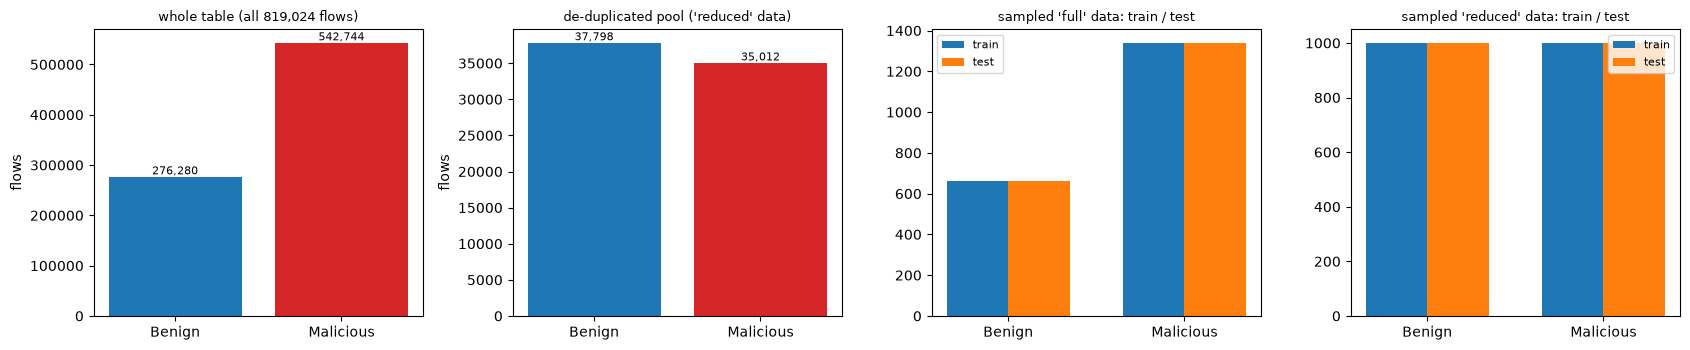

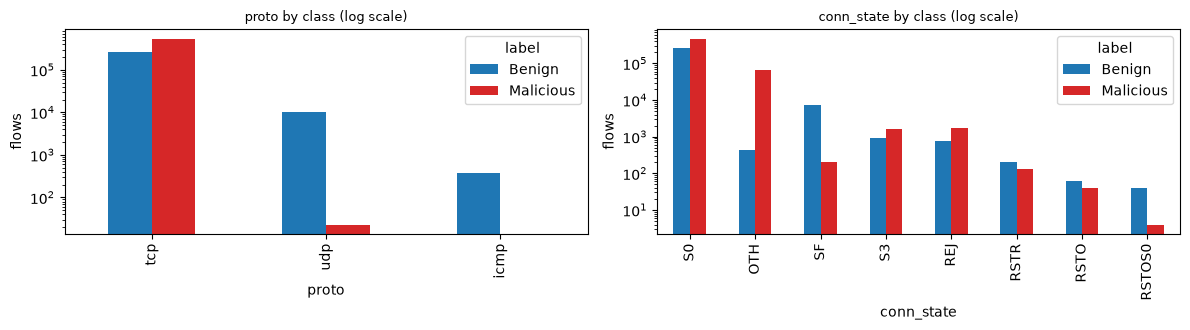

In [6]:
print("IoT-23 conn.log table (Hugging Face mirror) : shape =", raw.shape)
print("columns / dtypes:")
print(raw.drop(columns="y").dtypes.to_string())
print("\nfeatures used by the paper-style models (11):", FEATS)
print("original label values and counts:")
print(raw.label.value_counts().to_string())
print("\nrows with a missing duration / byte counts (Zeek '-'):", int(raw.duration.isna().sum()), f"({raw.duration.isna().mean():.1%})")
print("duplicate rows on the 11 features + label:", int(raw.duplicated(subset=FEATS + ['y']).sum()), "of", len(raw))
print("-> after removing them (the 'reduced' pool):", POOLS['reduced'].shape[0], "flows, label counts:")
print(POOLS["reduced"].label.value_counts().to_string())

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
col = {0: "tab:blue", 1: "tab:red"}
for ax, (title, d) in zip(axes[:2], [("whole table (all 819,024 flows)", raw), ("de-duplicated pool ('reduced' data)", POOLS["reduced"])]):
    vc = d.label.value_counts().reindex(["Benign", "Malicious"])
    ax.bar(vc.index, vc.values, color=["tab:blue", "tab:red"]); ax.set_title(title, fontsize=9); ax.set_ylabel("flows")
    for i, v in enumerate(vc.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
for ax, (title, ds) in zip(axes[2:], [("sampled 'full' data: train / test", get_dataset("full")), ("sampled 'reduced' data: train / test", get_dataset("reduced"))]):
    w = 0.35
    for k, (lab, y) in enumerate([("train", np.concatenate([ds["ytr"], ds["yva"]])), ("test", ds["yte"])]):
        ax.bar(np.arange(2) + (k - 0.5) * w, [np.sum(y == 0), np.sum(y == 1)], width=w, label=lab)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Benign", "Malicious"]); ax.set_title(title, fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# what the two categorical features look like per class (real flows, whole table)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, c in zip(axes, ["proto", "conn_state"]):
    ct = pd.crosstab(raw[c], raw.label).reindex(columns=["Benign", "Malicious"]).fillna(0)
    ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index[:8]]
    ct.plot(kind="bar", ax=ax, color=["tab:blue", "tab:red"], logy=True); ax.set_title(f"{c} by class (log scale)", fontsize=9); ax.set_ylabel("flows")
plt.tight_layout(); plt.show()


'full' data, 11 features, training flows - explained variance of the two components: [0.566 0.207]
'reduced' data, 8 features, training flows - explained variance of the two components: [0.535 0.257]


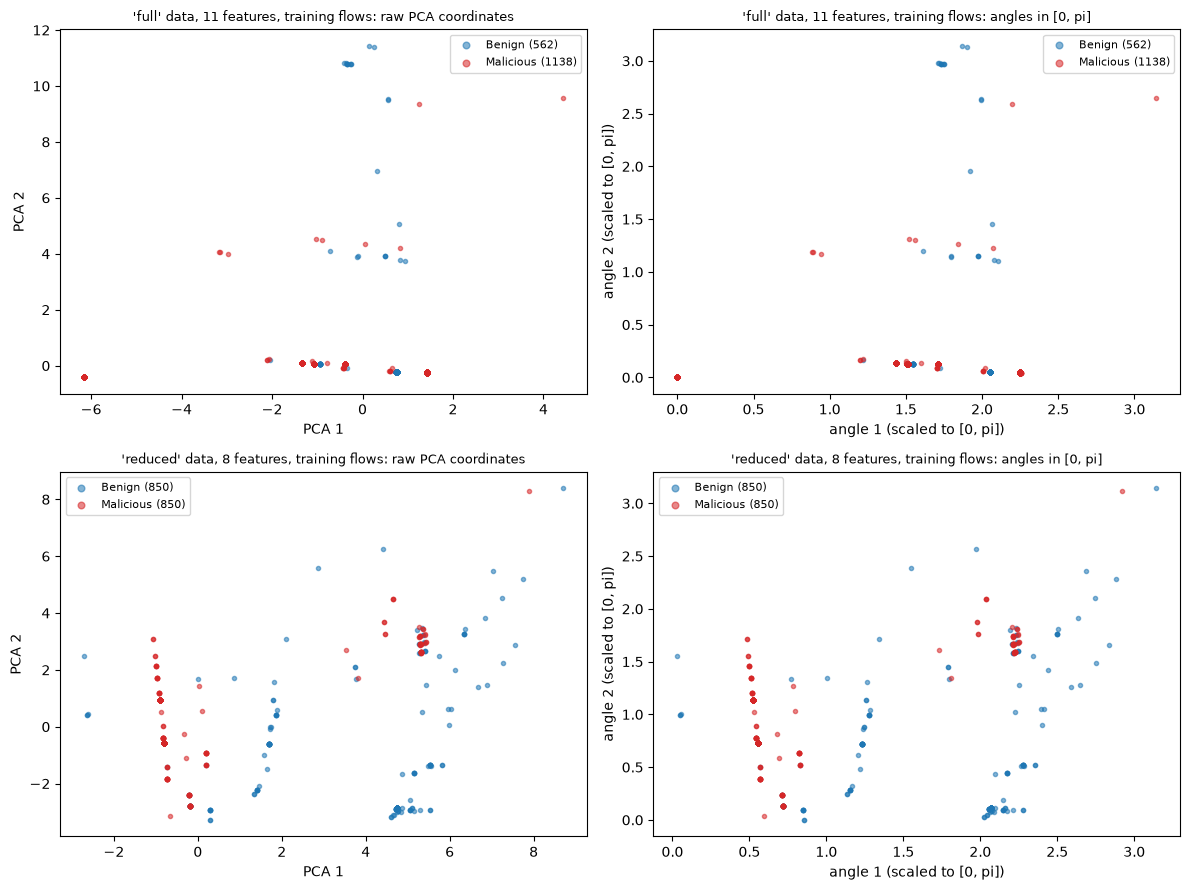

In [7]:
# 2-D scatter of the REAL training flows coloured by ground-truth label.
# Left: first two PCA coordinates (PCA fitted on the training split). Right: the same coordinates min-max scaled to [0, pi]
# (the range of a rotation angle; fitted on the training split, test values clipped).
def pca_scatter(ds, title, fig_axes):
    X, y = ds["Xtr"], ds["ytr"]
    pca = PCA(n_components=2, random_state=SEED).fit(X)
    Z = pca.transform(X)
    mm = MinMaxScaler((0, np.pi)).fit(Z)
    A = np.clip(mm.transform(Z), 0, np.pi)
    sel = np.random.default_rng(SEED).permutation(len(y))[:1500]             # draw at most 1500 points to keep the figure readable
    for ax, P, xl in zip(fig_axes, [Z, A], ["PCA 1", "angle 1 (scaled to [0, pi])"]):
        for lab, name, c in [(0, "Benign", "tab:blue"), (1, "Malicious", "tab:red")]:
            m = sel[y[sel] == lab]
            ax.scatter(P[m, 0], P[m, 1], s=9, alpha=0.55, c=c, label=f"{name} ({int((y == lab).sum())})")
        ax.set_xlabel(xl); ax.set_ylabel(xl.replace("1", "2")); ax.legend(fontsize=8, markerscale=1.6)
    fig_axes[0].set_title(title + ": raw PCA coordinates", fontsize=9)
    fig_axes[1].set_title(title + ": angles in [0, pi]", fontsize=9)
    print(title, "- explained variance of the two components:", pca.explained_variance_ratio_.round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
pca_scatter(get_dataset("full"), "'full' data, 11 features, training flows", axes[0])
pca_scatter(get_dataset("reduced"), "'reduced' data, 8 features, training flows", axes[1])
plt.tight_layout(); plt.show()


**Reading the plots.** The classes are not perfectly separated in the top two principal components, but the malicious flows (mostly
failed `S0` TCP connection attempts with 2 packets and no reply, as in Mirai-style scanning) form dense, well-defined regions. This is
why very small models already reach high accuracy on this data set, and why a stronger result for a QVC says little about quantum advantage.

## 3. The model: dense encoder, quantum variational circuit, vertical layers

One **block** is `Linear(features -> q)` (the feature transformation `phi`), a QVC on `q` qubits with `L` horizontal layers, and the
expectation value `<Z_i>` of every qubit. A **vertical model** concatenates the read-outs of `m` independent blocks and applies one shared
`Linear(sum of qubits -> 1)`. The cell below defines the circuit, a batched exact state-vector simulator for it (so that training is feasible),
the PennyLane version of the same circuit, and checks (a) simulator == PennyLane and (b) the parameter counts of the paper's tables.

Layer `l` of the circuit: `RY(phi_i)` on every qubit (data re-uploaded in every layer, as in eq. (3)), `RX(theta)` on every qubit, a CNOT
ring `0->1, 1->2, ..., (q-1)->0`, then `RZ(theta)` on every qubit (not after the last layer: a trailing `RZ` cannot change a Z-basis read-out).
That is `q(2L-1)` trainable angles per block. This layout is a **choice**, the paper does not print its gates; it was found by matching the
printed parameter counts, which it does for 15 of 16 models.

In [8]:
# ---------------------------------------------------------------------------------------------
# The quantum variational circuit (QVC) of one block, q qubits, L horizontal layers.
# Layer l = [ RY(phi_i) on every qubit ]  (data encoding, re-uploaded in every layer, eq. (3))
#           [ RX(wx[l,i]) on every qubit ]  (trainable)
#           [ CNOT ring 0->1, 1->2, ..., (q-1)->0 ]  (single CNOT for q = 2, none for q = 1)
#           [ RZ(wz[l,i]) on every qubit ]  (trainable; omitted in the last layer, it would not change a Z read-out)
# Read-out: <Z_i> for every qubit.  Trainable angles: q*L (RX) + q*(L-1) (RZ) = q*(2L-1).
# CHOICE: the paper gives no gate list. This layout reproduces EVERY parameter count of its Tables 1 to 3 exactly (checked below).
#
# Training runs on a hand-written, batched, differentiable state-vector simulator (torch autograd = exact gradients; the
# paper's parameter-shift rule gives the same numbers on a noiseless device). A PennyLane QNode with the SAME gates is built
# further down, asserted equal to the simulator, and is what gets drawn in the "Quantum Circuit Architecture" section.
# ---------------------------------------------------------------------------------------------
CD = torch.complex64

def _single(phi, wx):
    """Per-sample 2x2 matrix RX(wx) @ RY(phi) as four (B,) complex entries."""
    c, s = torch.cos(phi / 2), torch.sin(phi / 2)                    # RY(phi) = [[c, -s], [s, c]]
    cx, sx = torch.cos(wx / 2), torch.sin(wx / 2)                    # RX(wx)  = [[cx, -i sx], [-i sx, cx]]
    return (cx * c - 1j * sx * s, -cx * s - 1j * sx * c, -1j * sx * c + cx * s, 1j * sx * s + cx * c)

def _apply(psi, m, i, q):
    B = psi.shape[0]
    p = psi.reshape(B, 2 ** i, 2, 2 ** (q - 1 - i))
    p0, p1 = p[:, :, 0, :], p[:, :, 1, :]
    m00, m01, m10, m11 = [t.reshape(B, 1, 1) for t in m]
    return torch.stack([m00 * p0 + m01 * p1, m10 * p0 + m11 * p1], 2).reshape(B, -1)

def _ring_gather(q):
    """Index g with new_state = old_state[:, g] for the CNOT ring 0->1, 1->2, ..., (q-1)->0 (wire 0 = most significant bit)."""
    idx = np.arange(2 ** q); f = idx.copy()
    pairs = [(i, (i + 1) % q) for i in range(q)] if q > 2 else ([(0, 1)] if q == 2 else [])
    for c, t in pairs:
        f = np.where(((f >> (q - 1 - c)) & 1) == 1, f ^ (1 << (q - 1 - t)), f)
    g = np.empty_like(f); g[f] = idx
    return torch.tensor(g)

def _z_signs(q):
    idx = np.arange(2 ** q)
    return torch.tensor(np.stack([1 - 2 * ((idx >> (q - 1 - i)) & 1) for i in range(q)], 0), dtype=torch.float32)

def _rz_diag(a, q):
    ph = torch.stack([torch.exp(-0.5j * a.to(CD)), torch.exp(0.5j * a.to(CD))], -1)      # (q, 2)
    d = ph[0]
    for i in range(1, q): d = (d[:, None] * ph[i][None, :]).reshape(-1)
    return d

def qvc_expvals(phi, wx, wz, g, zs):
    """phi: (B, q) encoding angles, wx: (L, q), wz: (L-1, q) -> (B, q) expectation values <Z_i>."""
    B, q = phi.shape; L = wx.shape[0]
    psi = torch.zeros(B, 2 ** q, dtype=CD); psi[:, 0] = 1
    for l in range(L):
        for i in range(q):
            psi = _apply(psi, _single(phi[:, i], wx[l, i]), i, q)
        if q > 1: psi = psi[:, g]
        if l < L - 1: psi = psi * _rz_diag(wz[l], q)[None, :]
    return (psi.real ** 2 + psi.imag ** 2) @ zs.T

# ---- the same circuit as a PennyLane QNode (used for the equivalence check and for the drawings) ----
def pennylane_qnode(q, L):
    dev = qml.device("default.qubit", wires=q)
    @qml.qnode(dev, interface="torch")
    def circuit(phi, wx, wz):
        for l in range(L):
            for i in range(q): qml.RY(phi[..., i], wires=i)
            for i in range(q): qml.RX(wx[l, i], wires=i)
            if q == 2: qml.CNOT(wires=[0, 1])
            elif q > 2:
                for i in range(q): qml.CNOT(wires=[i, (i + 1) % q])
            if l < L - 1:
                for i in range(q): qml.RZ(wz[l, i], wires=i)
        return [qml.expval(qml.PauliZ(i)) for i in range(q)]
    return circuit

# ---- hybrid model: dense encoder phi_i -> QVC_i  (one or several blocks "vertically") -> shared dense read-out psi ----
class QVCBlock(nn.Module):
    def __init__(self, n_in, q, L):
        super().__init__()
        self.q, self.L = q, L
        self.pre = nn.Linear(n_in, q)                                                  # feature transformation phi_i (eq. 5)
        self.wx = nn.Parameter(INIT_SCALE * torch.randn(L, q))
        self.wz = nn.Parameter(INIT_SCALE * torch.randn(max(L - 1, 0), q))
        self.register_buffer("g", _ring_gather(q)); self.register_buffer("zs", _z_signs(q))
    def angles(self, x): return self.pre(x)
    def forward(self, x): return qvc_expvals(self.pre(x), self.wx, self.wz, self.g, self.zs)

class VerticalQVC(nn.Module):
    """m independent QVC blocks side by side (vertical layers) + one shared dense read-out; m = 1 is the plain baseline."""
    def __init__(self, n_in, qubits, layers):
        super().__init__()
        self.blocks = nn.ModuleList([QVCBlock(n_in, q, L) for q, L in zip(qubits, layers)])
        self.post = nn.Linear(sum(qubits), 1)                                           # post-processing psi, followed by a sigmoid
    def forward(self, x): return self.post(torch.cat([b(x) for b in self.blocks], dim=1)).squeeze(1)

class DNN(nn.Module):
    """Classical reference of the paper: dense layers with sigmoid activations."""
    def __init__(self, n_in, hidden):
        super().__init__()
        dims, layers = [n_in] + list(hidden), []
        for a, b in zip(dims[:-1], dims[1:]): layers += [nn.Linear(a, b), nn.Sigmoid()]
        self.net = nn.Sequential(*layers, nn.Linear(dims[-1], 1))
    def forward(self, x): return self.net(x).squeeze(1)

class BottleneckControl(nn.Module):
    """Control (not in the paper): the same dense encoder and read-out, but the QVC replaced by tanh -> no quantum part."""
    def __init__(self, n_in, q):
        super().__init__()
        self.pre, self.post = nn.Linear(n_in, q), nn.Linear(q, 1)
    def forward(self, x): return self.post(torch.tanh(self.pre(x))).squeeze(1)

def n_params(model): return sum(p.numel() for p in model.parameters())
def n_qvc_params(model): return sum(b.wx.numel() + b.wz.numel() for b in getattr(model, "blocks", []))

def build(spec, n_in):
    if spec["kind"] == "qvc":  return VerticalQVC(n_in, spec["qubits"], spec["layers"])
    if spec["kind"] == "dnn":  return DNN(n_in, spec["hidden"])
    if spec["kind"] == "ctrl": return BottleneckControl(n_in, spec["q"])
    raise ValueError(spec)

def spec_name(s):
    if s["kind"] == "qvc":  return "QVC " + ("+".join(f"{q}q x {L}L" for q, L in zip(s["qubits"], s["layers"])))
    if s["kind"] == "dnn":  return "DNN " + "-".join(map(str, s["hidden"]))
    return f"control (dense {s['q']} + tanh)"

# ---- equivalence check: simulator == PennyLane QNode (float tolerance of complex64), several shapes ----
g_ = torch.Generator().manual_seed(0)
for (q_, L_) in [(1, 2), (2, 2), (3, 3), (5, 4), (7, 2)]:
    blk = QVCBlock(11, q_, L_)
    x_ = torch.randn(3, 11, generator=g_)
    with torch.no_grad():
        mine = blk(x_).numpy()
        ref = np.stack([t.detach().numpy() for t in pennylane_qnode(q_, L_)(blk.angles(x_).double(), blk.wx.double(), blk.wz.double())], axis=-1)
    assert np.allclose(mine, ref, atol=2e-5), (q_, L_, np.abs(mine - ref).max())
print("simulator == PennyLane QNode for (qubits, layers) in (1,2) (2,2) (3,3) (5,4) (7,2): max |difference| < 2e-5")

# ---- the parameter counts the paper prints (Tables 1 to 3) must come out exactly ----
PAPER_COUNTS = [("qvc", [9], [6], 217), ("qvc", [7], [5], 155), ("qvc", [8], [3], 145), ("qvc", [11], [5], 243), ("qvc", [10], [6], 241),
                ("qvc", [7], [7], 183), ("qvc", [7, 6, 4], [3, 2, 3], 295), ("qvc", [7, 5, 3, 1], [3, 4, 2, 3], 293),
                ("qvc", [7, 5, 4], [4, 3, 4], 311), ("qvc", [7, 7, 5, 3], [4, 3, 2, 3], 419)]
rows = []
for kind, qs, Ls, target in PAPER_COUNTS:
    m = build(dict(kind=kind, qubits=qs, layers=Ls), 11)
    rows.append(dict(model=spec_name(dict(kind=kind, qubits=qs, layers=Ls)), features=11, params_notebook=n_params(m), params_paper=target))
for qs, Ls, target in [([7], [6], 148), ([5], [3], 76), ([5], [5], 96), ([6], [4], 103)]:
    m = build(dict(kind="qvc", qubits=qs, layers=Ls), 8)
    rows.append(dict(model=spec_name(dict(kind="qvc", qubits=qs, layers=Ls)), features=8, params_notebook=n_params(m), params_paper=target))
for hid, nin, target in [([40, 38], 11, 2077), ([23, 40], 8, 1208)]:
    rows.append(dict(model=spec_name(dict(kind="dnn", hidden=hid)), features=nin, params_notebook=n_params(build(dict(kind="dnn", hidden=hid), nin)), params_paper=target))
PARAM_CHECK = pd.DataFrame(rows); PARAM_CHECK["match"] = PARAM_CHECK.params_notebook == PARAM_CHECK.params_paper
display(PARAM_CHECK)
print(f"{int(PARAM_CHECK.match.sum())} of {len(PARAM_CHECK)} parameter counts printed in the paper's Tables 1 to 3 are reproduced exactly.")
# The one mismatch is the last row of Table 2 (qubits 7,7,5,3 / layers 4,3,2,3, printed as 419; this layout gives 401). Every other
# row, including the other three vertical models, matches, so the layout is right and that printed row is most likely a typo.
assert PARAM_CHECK.match.sum() >= len(PARAM_CHECK) - 1


simulator == PennyLane QNode for (qubits, layers) in (1,2) (2,2) (3,3) (5,4) (7,2): max |difference| < 2e-5


,model,features,params_notebook,params_paper,match
0,QVC 9q x 6L,11,217,217,True
1,QVC 7q x 5L,11,155,155,True
2,QVC 8q x 3L,11,145,145,True
3,QVC 11q x 5L,11,243,243,True
4,QVC 10q x 6L,11,241,241,True
5,QVC 7q x 7L,11,183,183,True
6,QVC 7q x 3L+6q x 2L+4q x 3L,11,295,295,True
7,QVC 7q x 3L+5q x 4L+3q x 2L+1q x 3L,11,293,293,True
8,QVC 7q x 4L+5q x 3L+4q x 4L,11,311,311,True
9,QVC 7q x 4L+7q x 3L+5q x 2L+3q x 3L,11,401,419,False


15 of 16 parameter counts printed in the paper's Tables 1 to 3 are reproduced exactly.


## 4. Training, and the classical references

`run(dataset, spec, lr, seed)` trains one model (Adam, binary cross-entropy, 10 epochs, shuffled mini-batches), evaluates it on the
validation and test splits and memoises the result. First the classical references that use exactly the same standardised inputs:
RandomForest and SVC(rbf) from scikit-learn, and the paper's sigmoid DNN (architectures from Tables 1 and 3).

In [9]:
def metrics(y, p):
    """Macro-averaged precision / recall / F1 (the paper's Tables print precision ~ accuracy, i.e. macro averages)."""
    yh = (p > 0.5).astype(int)
    return dict(acc=accuracy_score(y, yh), prec=precision_score(y, yh, average="macro", zero_division=0),
                rec=recall_score(y, yh, average="macro", zero_division=0), f1=f1_score(y, yh, average="macro", zero_division=0))

@torch.no_grad()
def predict(model, X, chunk=512):
    model.eval()
    out = [torch.sigmoid(model(torch.from_numpy(X[i:i + chunk]))) for i in range(0, len(X), chunk)]
    return torch.cat(out).numpy()

RESULTS, MODELS = {}, {}          # memo: one entry per (dataset, spec, lr, seed); trained models kept for later figures

def run(dataset, spec, lr, seed=SEED, keep_model=False):
    key = (dataset, spec_name(spec), lr, seed)
    if key in RESULTS: return RESULTS[key]
    ds = get_dataset(dataset, seed)
    torch.manual_seed(seed)
    model = build(spec, ds["Xtr"].shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr)                       # paper: Adam, no schedule
    lossf = nn.BCEWithLogitsLoss()
    Xtr, ytr = torch.from_numpy(ds["Xtr"]), torch.from_numpy(ds["ytr"]).float()
    gen = torch.Generator().manual_seed(seed)
    t0, curve = time.time(), []
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(ytr), generator=gen); tot = 0.0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            opt.zero_grad(); loss = lossf(model(Xtr[b]), ytr[b]); loss.backward(); opt.step()
            tot += loss.item() * len(b)
        curve.append(tot / len(perm))
    secs = time.time() - t0
    pv, pt = predict(model, ds["Xva"]), predict(model, ds["Xte"])
    r = dict(dataset=dataset, model=spec_name(spec), kind=spec["kind"], lr=lr, seed=seed,
             qubits=",".join(map(str, spec.get("qubits", []))), layers=",".join(map(str, spec.get("layers", []))),
             params=n_params(model), qvc_params=n_qvc_params(model), max_qubits=max(spec.get("qubits", [0])),
             val_acc=metrics(ds["yva"], pv)["acc"], **metrics(ds["yte"], pt), loss_last=curve[-1], seconds=secs, curve=curve, p_test=pt)
    RESULTS[key] = r
    MODELS[key] = model                                                      # models are tiny (< 500 parameters); kept for the figures
    return r

def table(keys_or_rows=None, dataset=None):
    df = pd.DataFrame(list(RESULTS.values())).drop(columns=["curve", "p_test"])
    return df if dataset is None else df[df.dataset == dataset]

SHOW = ["dataset", "model", "lr", "seed", "params", "val_acc", "acc", "prec", "rec", "f1", "seconds"]
# smoke test: one tiny model, 2 s
_t = run("full", dict(kind="qvc", qubits=[3], layers=[2]), 0.1, SEED)
print(f"smoke test (3 qubits, 2 layers, lr 0.1): test accuracy {_t['acc']:.4f}, {_t['seconds']:.1f} s for {EPOCHS} epochs on {len(get_dataset('full')['ytr'])} flows")


smoke test (3 qubits, 2 layers, lr 0.1): test accuracy 0.9905, 17.4 s for 10 epochs on 1700 flows


In [10]:
def sk_baseline(name, dataset):
    """Scikit-learn baselines on exactly the standardised inputs the hybrid models receive (train-core fit, test evaluation)."""
    ds = get_dataset(dataset)
    t0 = time.time()
    clf = {"RandomForest(200)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
           "SVC(rbf, C=1)": SVC(kernel="rbf", C=1.0, probability=False, random_state=SEED)}[name].fit(ds["Xtr"], ds["ytr"])
    yh = clf.predict(ds["Xte"])
    return dict(dataset=dataset, model=name, lr=np.nan, seed=SEED, params=np.nan, **metrics(ds["yte"], yh.astype(float)), seconds=time.time() - t0)

SK = pd.DataFrame([sk_baseline(m, d) for d in ("full", "reduced") for m in ("RandomForest(200)", "SVC(rbf, C=1)")])
print("Scikit-learn baselines on the same inputs (test split):")
display(SK[["dataset", "model", "acc", "prec", "rec", "f1", "seconds"]].round(4))

# the paper's classical reference: DNN with sigmoid activations; architecture and learning rate from Table 1 (full) and Table 3 (reduced)
t0 = time.time()
DNN_SPEC = {"full": dict(kind="dnn", hidden=[40, 38]), "reduced": dict(kind="dnn", hidden=[23, 40])}
for d in ("full", "reduced"):
    for lr in (0.1, 0.01):
        r = run(d, DNN_SPEC[d], lr)
        print(f"{d:8s} {r['model']:10s} lr {lr:<5} params {r['params']:5d} | val acc {r['val_acc']:.4f} | test acc {r['acc']:.4f} prec {r['prec']:.4f} rec {r['rec']:.4f} F1 {r['f1']:.4f} | {r['seconds']:.1f}s")
print(f"({time.time() - t0:.0f} s)")


Scikit-learn baselines on the same inputs (test split):


,dataset,model,acc,prec,rec,f1,seconds
0,full,RandomForest(200),0.9940,0.9956,0.9909,0.9932,2.5777
1,full,"SVC(rbf, C=1)",0.9735,0.9768,0.9634,0.9697,0.2267
2,reduced,RandomForest(200),0.9105,0.9181,0.9105,0.9101,2.3751
3,reduced,"SVC(rbf, C=1)",0.9005,0.9063,0.9005,0.9001,0.4944


full     DNN 40-38  lr 0.1   params  2077 | val acc 1.0000 | test acc 0.9945 prec 0.9959 rec 0.9917 F1 0.9938 | 2.4s


full     DNN 40-38  lr 0.01  params  2077 | val acc 0.9767 | test acc 0.9745 prec 0.9775 rec 0.9649 F1 0.9708 | 2.2s


reduced  DNN 23-40  lr 0.1   params  1208 | val acc 0.9300 | test acc 0.8900 prec 0.8944 rec 0.8900 F1 0.8897 | 2.5s


reduced  DNN 23-40  lr 0.01  params  1208 | val acc 0.9367 | test acc 0.8895 prec 0.8951 rec 0.8895 F1 0.8891 | 2.8s
(11 s)


## 5. Single QVCs: a sub-grid of Section 4.1

The paper trains every cell of a 56-cell grid (1 to 11 qubits, 1 to `max(q,7)` layers) for four learning rates and lists the six best by
*test* accuracy (Table 1). Here a sub-grid is trained (see `BASE_GRID`), and the winners are listed twice: ranked by **validation** accuracy
(unbiased) and ranked by test accuracy (what the paper's table does, optimistic by construction). The heat maps are the analogue of
appendix tables A1 to A5.

[ 1/28]  1 qubits x 1 layers, lr 0.1    params   15  val 0.9667  test 0.9685  (5s, total 5s)


[ 2/28]  1 qubits x 1 layers, lr 0.2    params   15  val 0.9633  test 0.9690  (5s, total 10s)


[ 3/28]  1 qubits x 3 layers, lr 0.1    params   19  val 0.9800  test 0.9800  (11s, total 21s)


[ 4/28]  1 qubits x 3 layers, lr 0.2    params   19  val 0.9800  test 0.9780  (10s, total 31s)


[ 5/28]  1 qubits x 5 layers, lr 0.1    params   23  val 0.9667  test 0.9685  (17s, total 48s)


...

[28/28]  8 qubits x 3 layers, lr 0.2    params  145  val 0.9733  test 0.9675  (94s, total 1486s)



Six best single-QVC baselines by VALIDATION accuracy (the honest way to select) with their TEST metrics:


,q,L,params,lr,val_acc,acc,prec,rec,f1,seconds
0,7,5,155,0.1,0.9967,0.9845,0.9842,0.9808,0.9824,116.8878
1,7,3,127,0.1,0.9967,0.9865,0.9880,0.9815,0.9847,67.1791
2,5,1,71,0.1,0.9933,0.9810,0.9789,0.9782,0.9785,13.1923
3,5,5,111,0.2,0.9933,0.9785,0.9781,0.9732,0.9756,30.8767
4,1,5,23,0.2,0.9933,0.9910,0.9925,0.9872,0.9898,16.3781
5,7,1,99,0.2,0.9933,0.9825,0.9826,0.9778,0.9801,18.4334


Same ranking by TEST accuracy (what the paper's Table 1 does; optimistic because the test split picks the winner):


,q,L,params,lr,val_acc,acc,prec,rec,f1
0,1,5,23,0.2,0.9933,0.9910,0.9925,0.9872,0.9898
1,3,2,49,0.1,0.9900,0.9905,0.9910,0.9876,0.9892
2,7,3,127,0.1,0.9967,0.9865,0.9880,0.9815,0.9847
3,7,5,155,0.1,0.9967,0.9845,0.9842,0.9808,0.9824
4,3,1,43,0.1,0.9767,0.9835,0.9786,0.9846,0.9815
5,3,3,55,0.1,0.9867,0.9830,0.9823,0.9793,0.9807


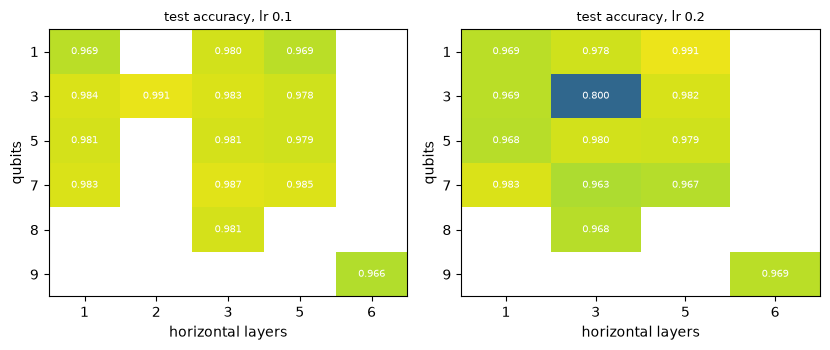

In [11]:
qvc1 = lambda q, L: dict(kind="qvc", qubits=[q], layers=[L])
jobs = [(q, L, lr) for (q, L) in BASE_GRID for lr in BASE_LRS if not (q >= 8 and lr < 0.1)] + list(BIG_RUNS)
t0 = time.time()
for k, (q, L, lr) in enumerate(jobs, 1):
    r = run("full", qvc1(q, L), lr)
    print(f"[{k:2d}/{len(jobs)}] {q:2d} qubits x {L} layers, lr {lr:<5}  params {r['params']:4d}  val {r['val_acc']:.4f}  test {r['acc']:.4f}  ({r['seconds']:.0f}s, total {time.time() - t0:.0f}s)", flush=True)

G = table(dataset="full"); G = G[G.kind == "qvc"].copy()
G["q"] = G.qubits.astype(int); G["L"] = G.layers.astype(int)
print("\nSix best single-QVC baselines by VALIDATION accuracy (the honest way to select) with their TEST metrics:")
display(G.sort_values("val_acc", ascending=False).head(6)[["q", "L", "params", "lr", "val_acc", "acc", "prec", "rec", "f1", "seconds"]].round(4).reset_index(drop=True))
print("Same ranking by TEST accuracy (what the paper's Table 1 does; optimistic because the test split picks the winner):")
display(G.sort_values("acc", ascending=False).head(6)[["q", "L", "params", "lr", "val_acc", "acc", "prec", "rec", "f1"]].round(4).reset_index(drop=True))

fig, axes = plt.subplots(1, len(BASE_LRS), figsize=(4.2 * len(BASE_LRS), 3.6), squeeze=False)
for ax, lr in zip(axes[0], BASE_LRS):
    M = G[G.lr == lr].pivot_table(index="q", columns="L", values="acc")
    im = ax.imshow(M.values, vmin=0.7, vmax=1.0, cmap="viridis", aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M.values[i, j]): ax.text(j, i, f"{M.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=7)
    ax.set_title(f"test accuracy, lr {lr}", fontsize=9); ax.set_xlabel("horizontal layers"); ax.set_ylabel("qubits")
plt.tight_layout(); plt.show()


## 6. Vertical layers (Section 4.2, Table 2)

The four vertical architectures the paper's Optuna search found, one per learning rate, are trained as they are. Each block has its own
dense encoder `phi_i`, so a block only sees the features through its own small bottleneck; the blocks never exchange quantum information.

In [12]:
# The four vertical-layer architectures the paper reports in Table 2 (learning rate -> qubits per block / layers per block).
# CHOICE: the paper found them with Optuna (90 trials per learning rate); that search is not repeated here, its four winners are trained.
VERT = {0.2: dict(kind="qvc", qubits=[7, 6, 4], layers=[3, 2, 3]),
        0.1: dict(kind="qvc", qubits=[7, 5, 3, 1], layers=[3, 4, 2, 3]),
        0.01: dict(kind="qvc", qubits=[7, 5, 4], layers=[4, 3, 4]),
        0.001: dict(kind="qvc", qubits=[7, 7, 5, 3], layers=[4, 3, 2, 3])}
t0 = time.time()
for lr in VERT_LRS:
    r = run("full", VERT[lr], lr)
    print(f"lr {lr:<6} {r['model']:38s} params {r['params']:4d}  val {r['val_acc']:.4f}  test {r['acc']:.4f}  F1 {r['f1']:.4f}  ({r['seconds']:.0f}s)", flush=True)
V = table(dataset="full"); V = V[V.model.str.contains(r"L\+", regex=True)]
display(V[["model", "lr", "params", "val_acc", "acc", "prec", "rec", "f1", "seconds"]].round(4).reset_index(drop=True))
print(f"({time.time() - t0:.0f} s)")


lr 0.2    QVC 7q x 3L+6q x 2L+4q x 3L            params  295  val 0.9900  test 0.9810  F1 0.9784  (140s)


lr 0.1    QVC 7q x 3L+5q x 4L+3q x 2L+1q x 3L    params  293  val 0.9900  test 0.9885  F1 0.9870  (163s)


lr 0.01   QVC 7q x 4L+5q x 3L+4q x 4L            params  311  val 0.9767  test 0.9750  F1 0.9714  (167s)


lr 0.001  QVC 7q x 4L+7q x 3L+5q x 2L+3q x 3L    params  401  val 0.9767  test 0.9720  F1 0.9679  (148s)


,model,lr,params,val_acc,acc,prec,rec,f1,seconds
0,QVC 7q x 3L+6q x 2L+4q x 3L,0.200,295,0.9900,0.9810,0.9827,0.9744,0.9784,139.7618
1,QVC 7q x 3L+5q x 4L+3q x 2L+1q x 3L,0.100,293,0.9900,0.9885,0.9876,0.9864,0.9870,163.1239
2,QVC 7q x 4L+5q x 3L+4q x 4L,0.010,311,0.9767,0.9750,0.9783,0.9653,0.9714,167.0304
3,QVC 7q x 4L+7q x 3L+5q x 2L+3q x 3L,0.001,401,0.9767,0.9720,0.9753,0.9615,0.9679,147.9428


(625 s)


## 7. The reduced data set (Section 4.3, Table 3)

Same single-QVC experiment on the de-duplicated, class-balanced data with the three weakest features removed (8 features, so at most
8 qubits would be meaningful). Note that the reduced data are a *different, harder* sample than the full data (no duplicates, 50/50 classes),
so accuracies are not directly comparable across the two data sets.

In [13]:
t0 = time.time()
for (q, L) in RED_GRID:
    for lr in RED_LRS:
        r = run("reduced", qvc1(q, L), lr)
        print(f"reduced: {q} qubits x {L} layers, lr {lr:<5} params {r['params']:4d}  val {r['val_acc']:.4f}  test {r['acc']:.4f}  ({r['seconds']:.0f}s)", flush=True)
R = table(dataset="reduced"); R = R[R.kind == "qvc"]
print("\nReduced data (8 features), single QVCs, ranked by validation accuracy:")
display(R.sort_values("val_acc", ascending=False).head(6)[["model", "params", "lr", "val_acc", "acc", "prec", "rec", "f1"]].round(4).reset_index(drop=True))
print(f"({time.time() - t0:.0f} s)")


reduced: 5 qubits x 3 layers, lr 0.1   params   76  val 0.9333  test 0.8845  (39s)


reduced: 5 qubits x 3 layers, lr 0.2   params   76  val 0.8833  test 0.8580  (39s)


reduced: 5 qubits x 5 layers, lr 0.1   params   96  val 0.9200  test 0.8865  (65s)


reduced: 5 qubits x 5 layers, lr 0.2   params   96  val 0.8833  test 0.8545  (63s)


reduced: 6 qubits x 4 layers, lr 0.1   params  103  val 0.9167  test 0.8690  (58s)


...

reduced: 7 qubits x 6 layers, lr 0.1   params  148  val 0.8767  test 0.8565  (152s)


reduced: 7 qubits x 6 layers, lr 0.2   params  148  val 0.8500  test 0.8260  (147s)



Reduced data (8 features), single QVCs, ranked by validation accuracy:


,model,params,lr,val_acc,acc,prec,rec,f1
0,QVC 5q x 3L,76,0.1,0.9333,0.8845,0.8921,0.8845,0.8839
1,QVC 5q x 5L,96,0.1,0.9200,0.8865,0.8922,0.8865,0.8861
2,QVC 6q x 4L,103,0.1,0.9167,0.8690,0.8819,0.8690,0.8679
3,QVC 5q x 3L,76,0.2,0.8833,0.8580,0.8676,0.8580,0.8571
4,QVC 5q x 5L,96,0.2,0.8833,0.8545,0.8701,0.8545,0.8530
5,QVC 7q x 6L,148,0.1,0.8767,0.8565,0.8703,0.8565,0.8552


(625 s)


## 8. The paper's headline models over several seeds

A single run says little at this sample size, so the paper's own headline architectures are repeated with different data draws, splits and
initialisations (`N_SEEDS`). They are fixed in advance, nothing is picked on the test split. The **control** replaces the QVC by a `tanh`
layer between the same dense encoder and read-out; if the control matches the QVC, the quantum part is not what makes the model work.

full     single QVC 7q x 5L, lr 0.2 (Table 1 row 2)              done (188 s)


full     vertical 7+6+4 qubits, lr 0.2 (Table 2 row 1)           done (421 s)


full     vertical 7+5+3+1 qubits, lr 0.1 (Table 2 row 2)         done (662 s)


full     classical DNN 40-38, lr 0.1 (Table 1)                   done (665 s)


full     control: dense 7 + tanh, no quantum part                done (669 s)


reduced  single QVC 7q x 6L, lr 0.2 (Table 3 row 1)              done (901 s)


reduced  classical DNN 23-40, lr 0.1 (Table 3)                   done (906 s)


reduced  control: dense 7 + tanh, no quantum part                done (911 s)



Mean +- std over 3 seeds (test split):


,dataset,label,params,acc_mean,acc_std,prec,rec,f1_mean,f1_std,seconds
0,full,"single QVC 7q x 5L, lr 0.2 (Table 1 row 2)",155,0.9762,0.0088,0.9790,0.9676,0.9730,0.0103,90.2820
1,full,"vertical 7+6+4 qubits, lr 0.2 (Table 2 row 1)",295,0.9825,0.0018,0.9830,0.9779,0.9803,0.0021,123.5794
2,full,"vertical 7+5+3+1 qubits, lr 0.1 (Table 2 row 2)",293,0.9775,0.0186,0.9783,0.9715,0.9747,0.0210,134.1934
3,full,"classical DNN 40-38, lr 0.1 (Table 1)",2077,0.9903,0.0077,0.9920,0.9865,0.9891,0.0087,1.5860
4,full,"control: dense 7 + tanh, no quantum part",92,0.9947,0.0025,0.9952,0.9930,0.9940,0.0027,1.2833
5,reduced,"single QVC 7q x 6L, lr 0.2 (Table 3 row 1)",148,0.8313,0.0343,0.8426,0.8313,0.8301,0.0341,125.4687
6,reduced,"classical DNN 23-40, lr 0.1 (Table 3)",1208,0.8878,0.0188,0.8965,0.8878,0.8871,0.0197,2.3187
7,reduced,"control: dense 7 + tanh, no quantum part",71,0.8853,0.0146,0.8939,0.8853,0.8847,0.0150,1.6305


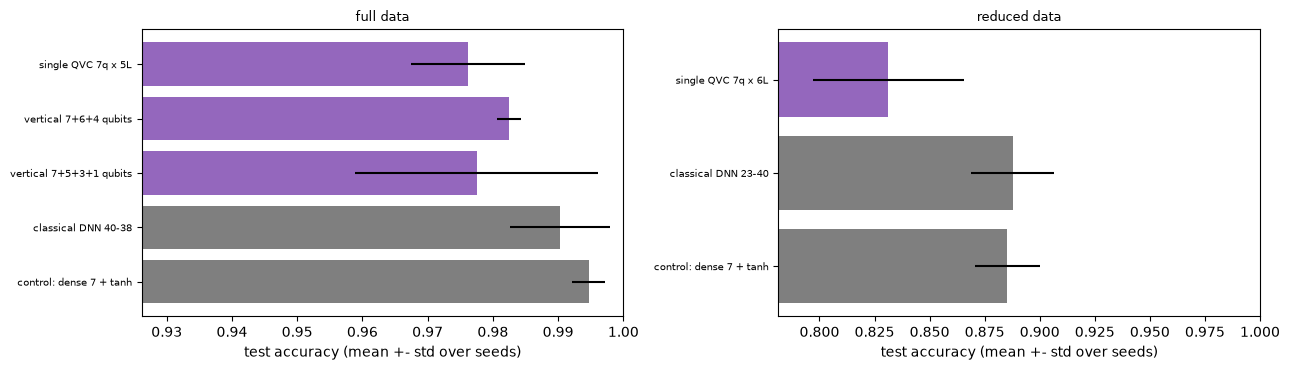

In [14]:
# Headline models of the paper, repeated over seeds (a different data draw, split and initialisation per seed).
# These are the paper's own architectures, fixed in advance: nothing is selected on the test split here.
HEAD_FULL = [("single QVC 7q x 5L, lr 0.2 (Table 1 row 2)", qvc1(7, 5), 0.2),
             ("vertical 7+6+4 qubits, lr 0.2 (Table 2 row 1)", VERT[0.2], 0.2),
             ("vertical 7+5+3+1 qubits, lr 0.1 (Table 2 row 2)", VERT[0.1], 0.1),
             ("classical DNN 40-38, lr 0.1 (Table 1)", DNN_SPEC["full"], 0.1),
             ("control: dense 7 + tanh, no quantum part", dict(kind="ctrl", q=7), 0.1)]
if HEADLINE_BIG:
    HEAD_FULL.insert(0, ("single QVC 9q x 6L, lr 0.1 (Table 1 row 1)", qvc1(9, 6), 0.1))
HEAD_RED = [("single QVC 7q x 6L, lr 0.2 (Table 3 row 1)", qvc1(7, 6), 0.2),
            ("classical DNN 23-40, lr 0.1 (Table 3)", DNN_SPEC["reduced"], 0.1),
            ("control: dense 7 + tanh, no quantum part", dict(kind="ctrl", q=7), 0.1)]
t0 = time.time(); rows = []
for dataset, heads in (("full", HEAD_FULL), ("reduced", HEAD_RED)):
    for label, spec, lr in heads:
        for s in range(N_SEEDS):
            r = run(dataset, spec, lr, SEED + s)
            rows.append(dict(dataset=dataset, label=label, seed=SEED + s, params=r["params"], acc=r["acc"], prec=r["prec"], rec=r["rec"], f1=r["f1"], seconds=r["seconds"]))
        print(f"{dataset:8s} {label:55s} done ({time.time() - t0:.0f} s)", flush=True)
HEAD = pd.DataFrame(rows)
SUMM = HEAD.groupby(["dataset", "label"], sort=False).agg(params=("params", "first"), acc_mean=("acc", "mean"), acc_std=("acc", "std"),
                                                          prec=("prec", "mean"), rec=("rec", "mean"), f1_mean=("f1", "mean"), f1_std=("f1", "std"),
                                                          seconds=("seconds", "mean")).reset_index()
print(f"\nMean +- std over {N_SEEDS} seeds (test split):")
display(SUMM.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, dataset in zip(ax, ("full", "reduced")):
    S = SUMM[SUMM.dataset == dataset]
    a.barh(range(len(S)), S.acc_mean, xerr=S.acc_std.fillna(0), color=["tab:purple" if "QVC" in l or "vertical" in l else "tab:gray" for l in S.label])
    a.set_yticks(range(len(S))); a.set_yticklabels([l.split(",")[0] for l in S.label], fontsize=7); a.invert_yaxis()
    a.set_xlim(max(0.5, S.acc_mean.min() - 0.05), 1.0); a.set_xlabel("test accuracy (mean +- std over seeds)"); a.set_title(f"{dataset} data", fontsize=9)
plt.tight_layout(); plt.show()


## 9. Confusion matrices and what the encoder hands to the circuit

Malicious is the positive class (false-negative rate = missed attacks). The last figure shows two of the angles that the trained dense
encoder feeds into the first qubits, for real test flows coloured by their true label.

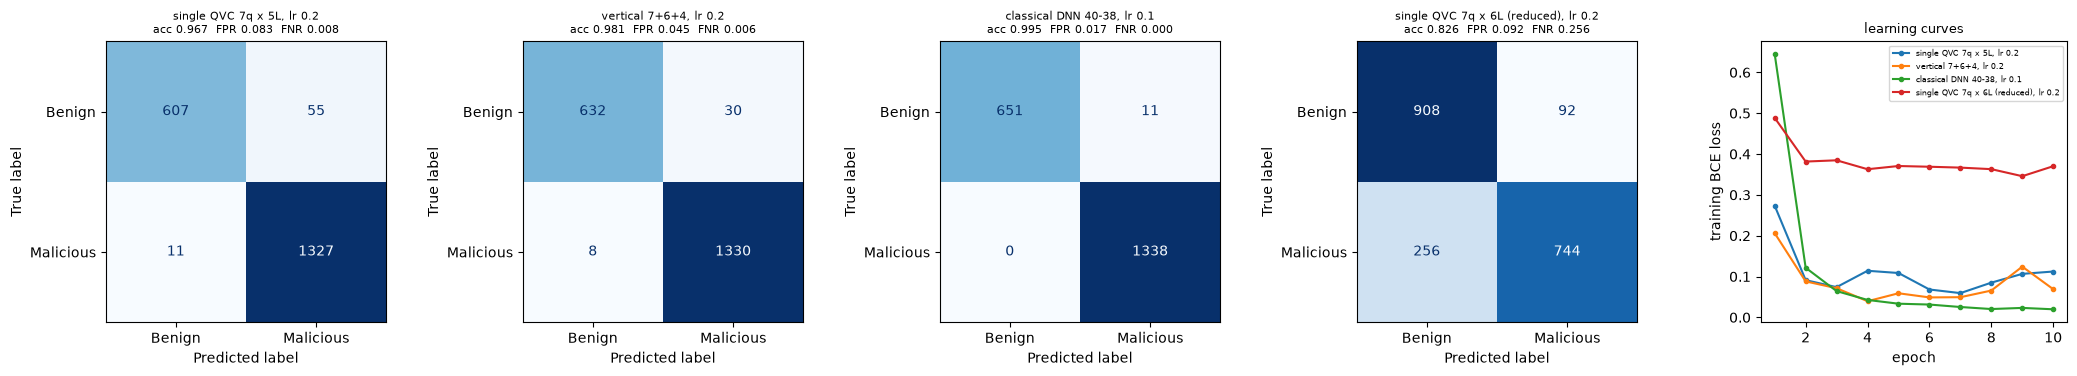

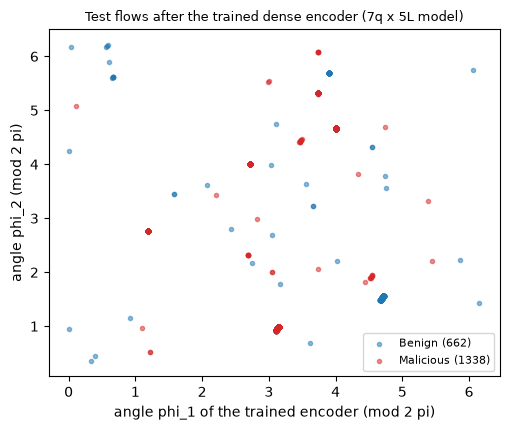

In [15]:
# Confusion matrices (malicious = positive class) and training-loss curves for the main models on the 'full' data, seed SEED.
show = [("single QVC 7q x 5L, lr 0.2", "full", qvc1(7, 5), 0.2), ("vertical 7+6+4, lr 0.2", "full", VERT[0.2], 0.2),
        ("classical DNN 40-38, lr 0.1", "full", DNN_SPEC["full"], 0.1), ("single QVC 7q x 6L (reduced), lr 0.2", "reduced", qvc1(7, 6), 0.2)]
fig, axes = plt.subplots(1, 5, figsize=(21, 3.8))
for ax, (title, dsn, spec, lr) in zip(axes[:4], show):
    r = run(dsn, spec, lr, SEED); ds = get_dataset(dsn)
    cm = confusion_matrix(ds["yte"], (r["p_test"] > 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malicious"]).plot(ax=ax, colorbar=False, cmap="Blues")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{title}\nacc {r['acc']:.3f}  FPR {fp / max(fp + tn, 1):.3f}  FNR {fn / max(fn + tp, 1):.3f}", fontsize=8)
for title, dsn, spec, lr in show:
    axes[4].plot(range(1, EPOCHS + 1), run(dsn, spec, lr, SEED)["curve"], marker="o", ms=3, label=title)
axes[4].set_xlabel("epoch"); axes[4].set_ylabel("training BCE loss"); axes[4].legend(fontsize=6); axes[4].set_title("learning curves", fontsize=9)
plt.tight_layout(); plt.show()

# What the trained encoder hands to the circuit: the first two angles phi_1, phi_2 of the 7-qubit baseline for REAL test flows, coloured by label.
mdl = MODELS[("full", spec_name(qvc1(7, 5)), 0.2, SEED)]
dsf = get_dataset("full")
with torch.no_grad():
    ang = mdl.blocks[0].angles(torch.from_numpy(dsf["Xte"])).numpy()
ang = np.mod(ang, 2 * np.pi)                                         # a rotation angle is only defined modulo 2 pi
fig, ax = plt.subplots(1, 1, figsize=(5.2, 4.4))
for lab, name, c in [(0, "Benign", "tab:blue"), (1, "Malicious", "tab:red")]:
    m = dsf["yte"] == lab
    ax.scatter(ang[m, 0], ang[m, 1], s=9, alpha=0.5, c=c, label=f"{name} ({int(m.sum())})")
ax.set_xlabel("angle phi_1 of the trained encoder (mod 2 pi)"); ax.set_ylabel("angle phi_2 (mod 2 pi)"); ax.legend(fontsize=8)
ax.set_title("Test flows after the trained dense encoder (7q x 5L model)", fontsize=9)
plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

The drawings below are made by `qml.draw_mpl` from the **PennyLane QNode that is asserted equal** (on real test flows) to the simulator that
did the training, with the trained weights and the encoder angles of one real flow. They show, for each distinct architecture: the
data-encoding `RY` gates (re-uploaded in every layer), the trainable `RX` / `RZ` gates, the CNOT ring, and the Z-basis measurements
(`<Z>` on every qubit). The printed numbers are qubits, circuit depth, gate count, trainable circuit angles and the parameters of the
classical dense encoder in front of the block.

Assumptions where the paper is silent: the choice of trainable gates (`RX`, `RZ`), the entangler (CNOT ring) and the read-out (`<Z>` on all
qubits) are **ours**, calibrated by the paper's parameter counts; the paper only draws `RY` encodings (Fig. 1) and does not print the
trainable block `U(theta)`. A 9-qubit drawing is included because the paper's best baseline has that size; models with other sizes
(for example 7 qubits x 6 layers on the reduced data) use the same layer pattern.

Matplotlib is building the font cache; this may take a moment.


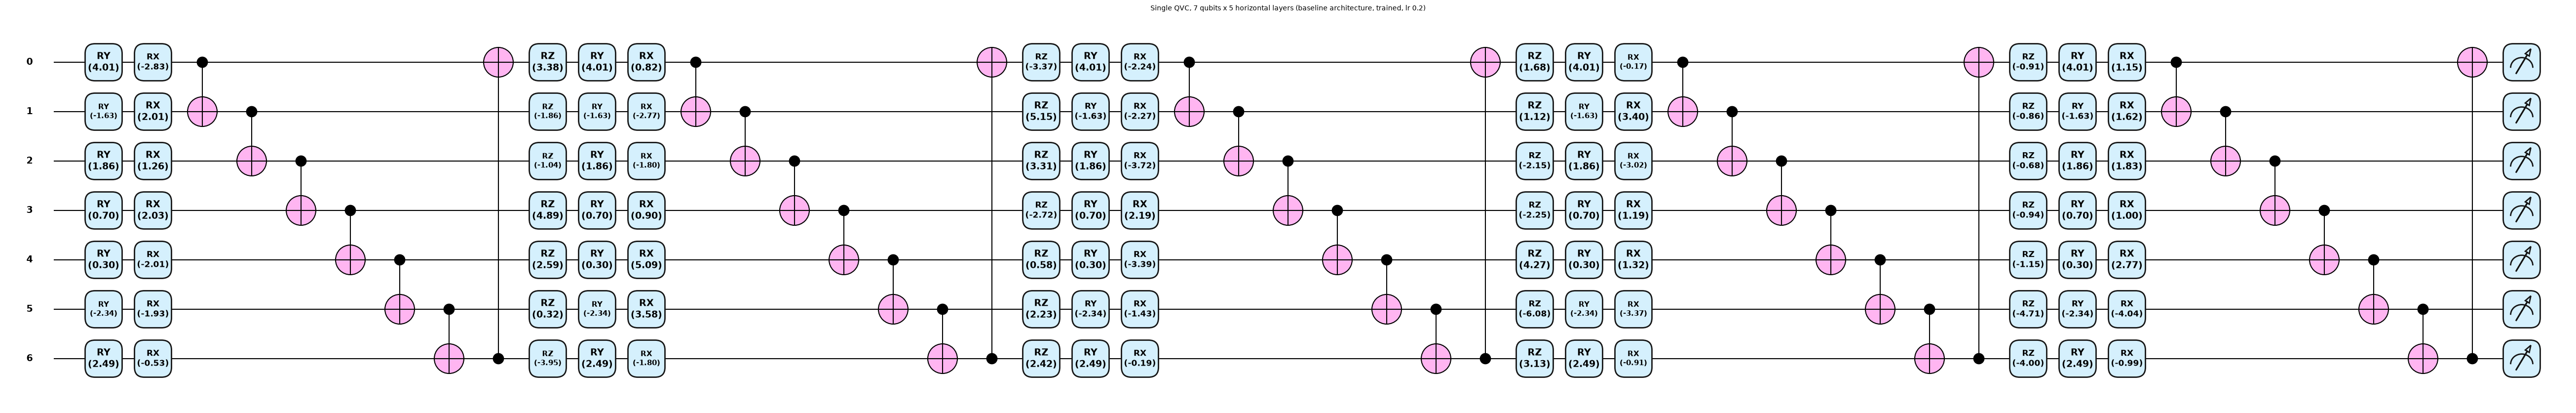

  qubits = 7 | depth = 49 | gates = 133 | trainable circuit parameters = 63 (= q*(2L-1) = 63) | classical encoder parameters = 84 | measurements: <Z> on each of the 7 qubits
  simulator == QNode on 4 real test flows (max |difference| = 1.5e-07)


Matplotlib is building the font cache; this may take a moment.


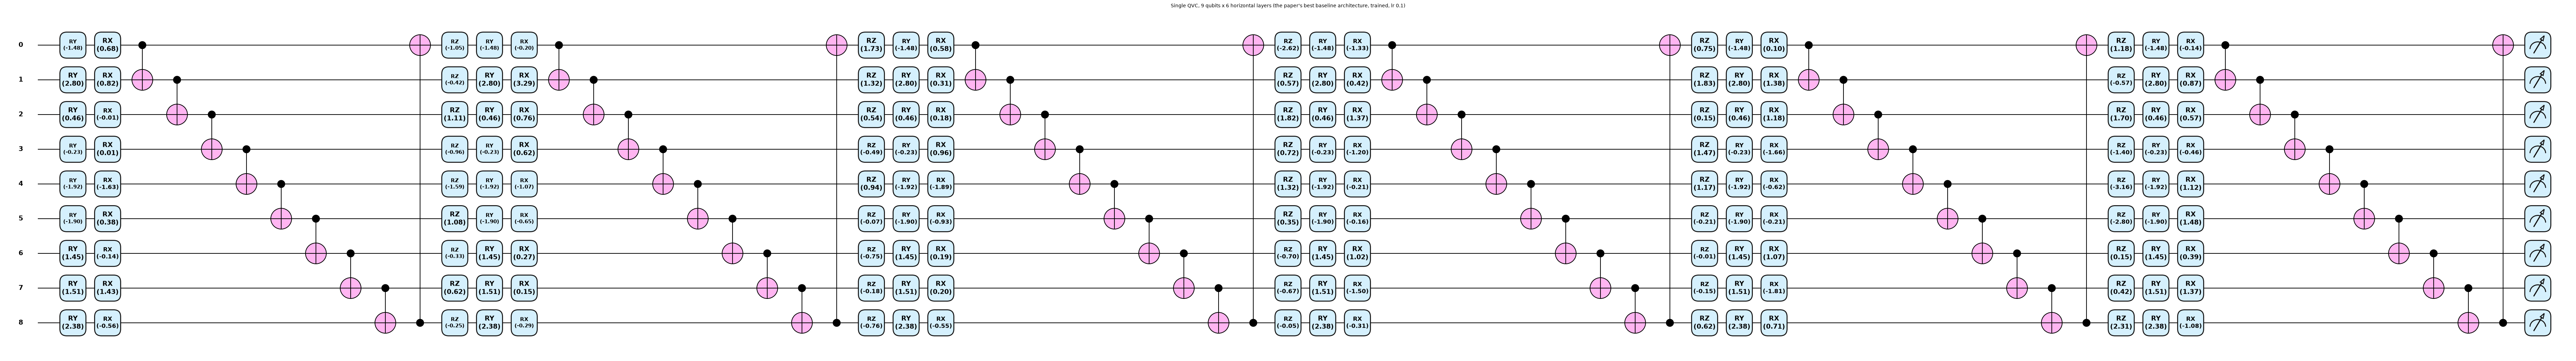

  qubits = 9 | depth = 71 | gates = 207 | trainable circuit parameters = 99 (= q*(2L-1) = 99) | classical encoder parameters = 108 | measurements: <Z> on each of the 9 qubits
  simulator == QNode on 4 real test flows (max |difference| = 1.8e-07)


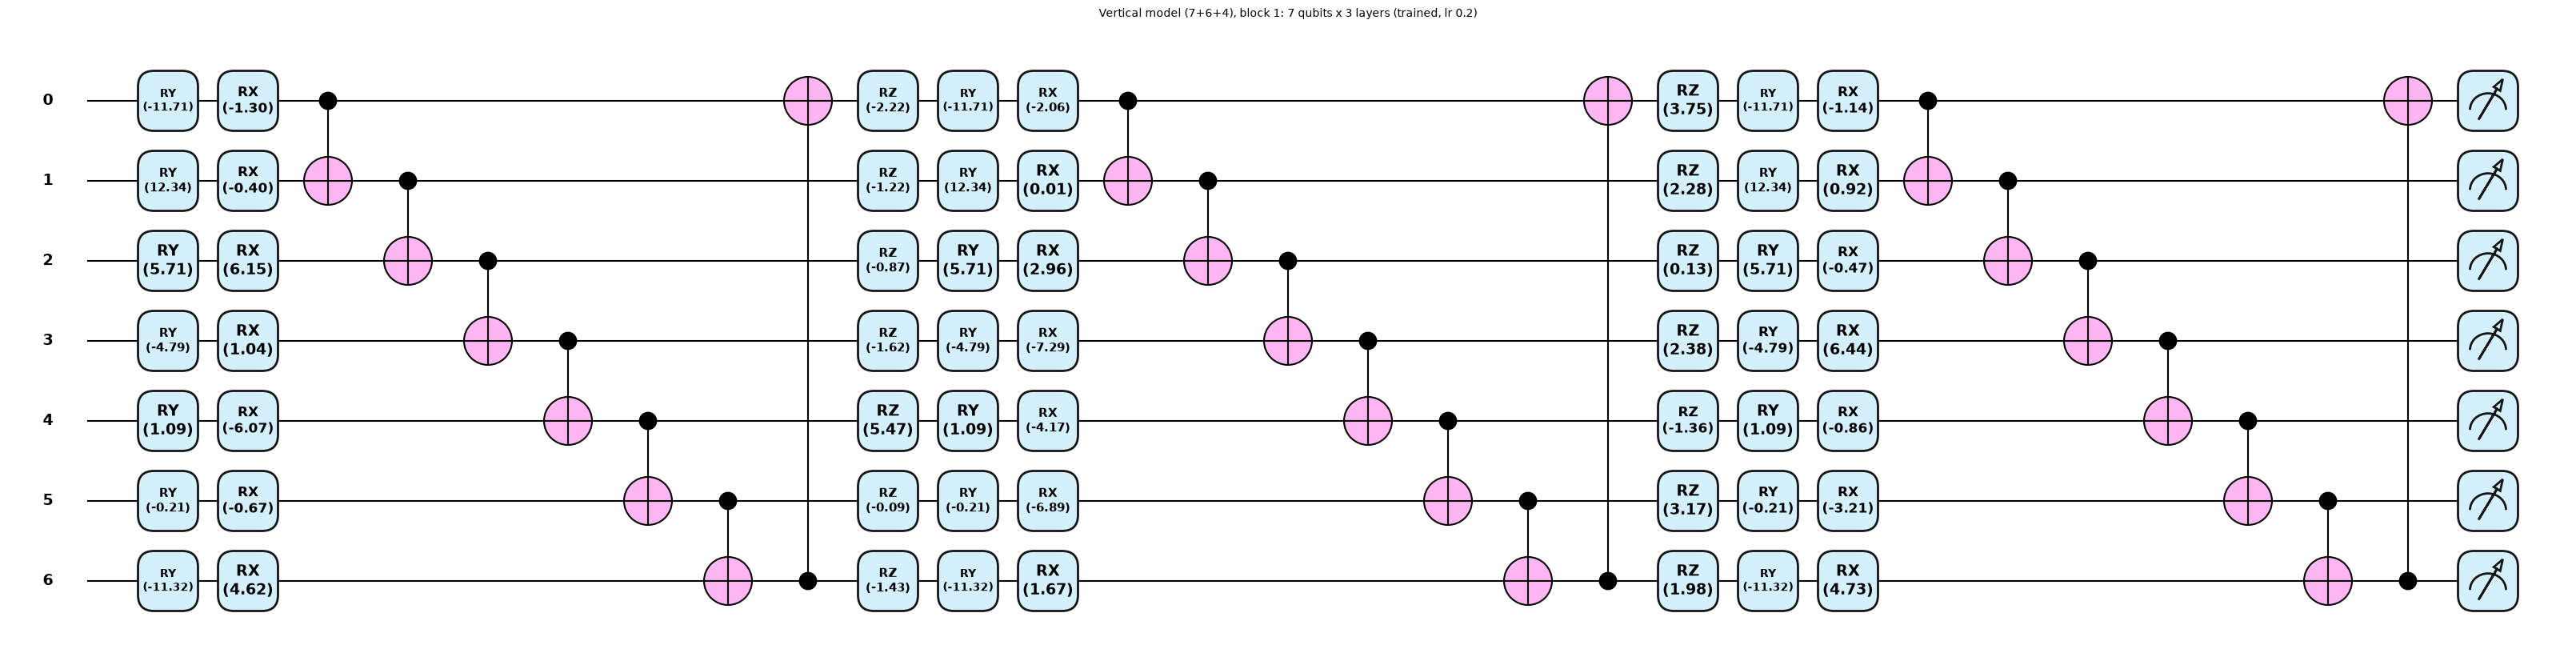

  qubits = 7 | depth = 29 | gates = 77 | trainable circuit parameters = 35 (= q*(2L-1) = 35) | classical encoder parameters = 84 | measurements: <Z> on each of the 7 qubits
  simulator == QNode on 4 real test flows (max |difference| = 1.5e-07)


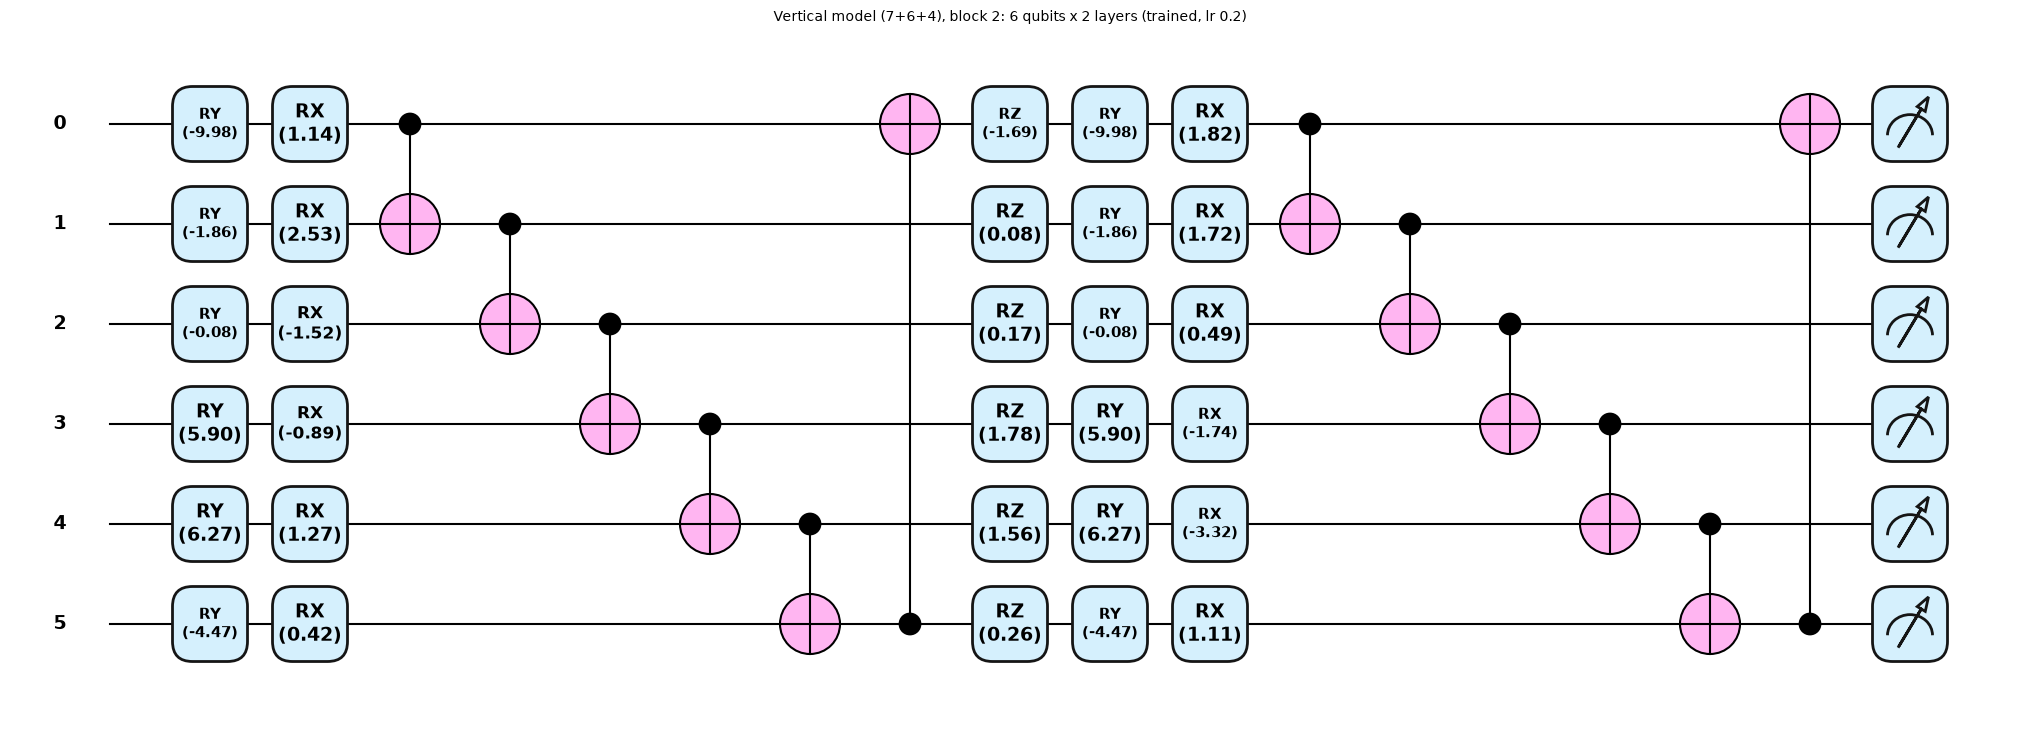

  qubits = 6 | depth = 17 | gates = 42 | trainable circuit parameters = 18 (= q*(2L-1) = 18) | classical encoder parameters = 72 | measurements: <Z> on each of the 6 qubits
  simulator == QNode on 4 real test flows (max |difference| = 3.7e-07)


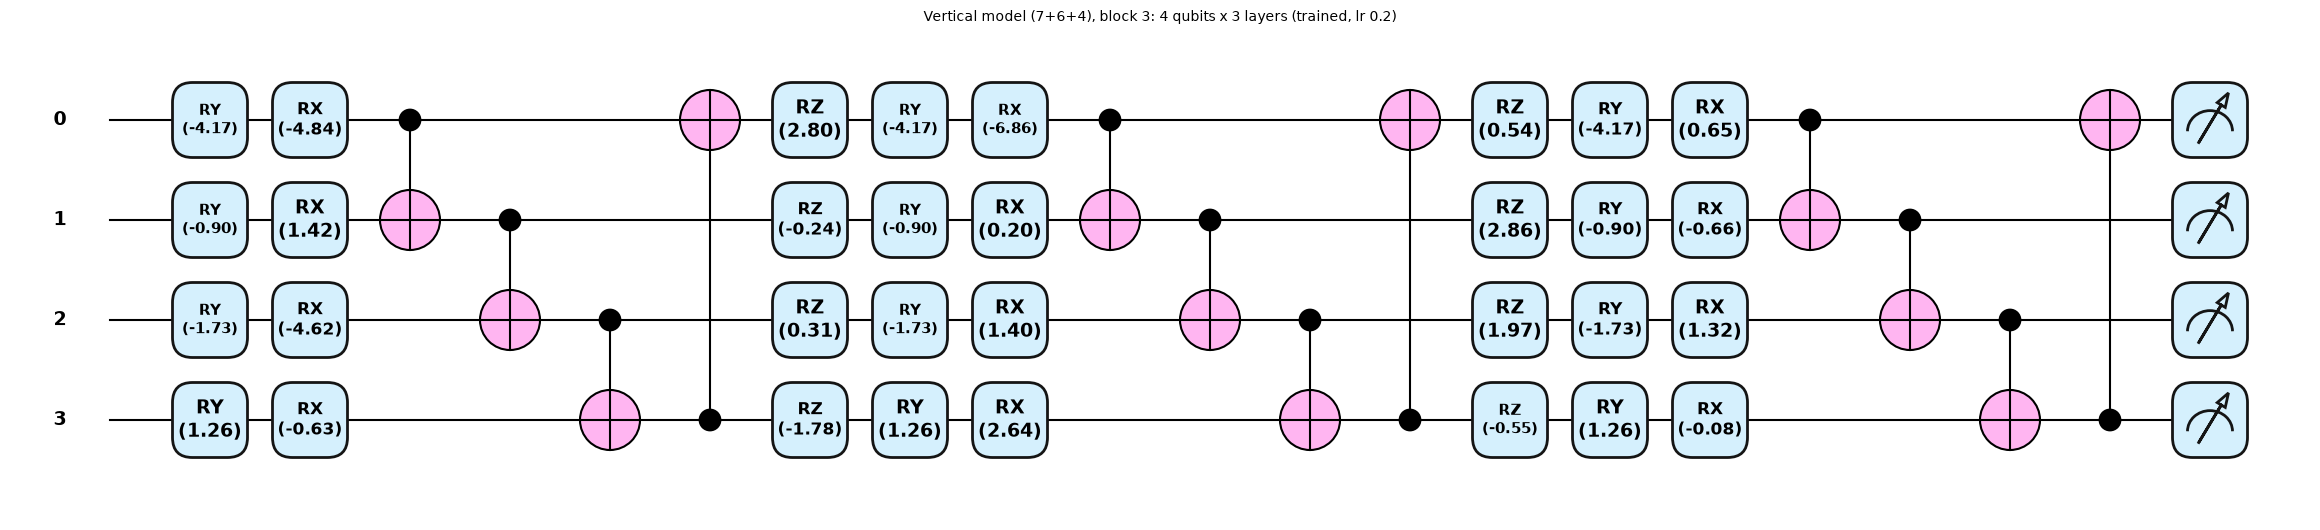

  qubits = 4 | depth = 20 | gates = 44 | trainable circuit parameters = 20 (= q*(2L-1) = 20) | classical encoder parameters = 48 | measurements: <Z> on each of the 4 qubits
  simulator == QNode on 4 real test flows (max |difference| = 1.3e-07)

The vertical model runs its three blocks as independent circuits on separate (small) devices; only their <Z> read-outs are
concatenated and sent through the shared dense layer. The reduced-data 7q x 6L model uses the same layer pattern as the 7q x 5L drawing.


In [16]:
# Draw the circuits that were actually trained and executed: the PennyLane QNode with the trained weights, one drawing per distinct
# architecture. The simulator that did the training is asserted equal to this QNode on real test flows first.
def circuit_report(dataset, spec, lr, which, title):
    key = (dataset, spec_name(spec), lr, SEED)
    run(dataset, spec, lr, SEED)
    blk = MODELS[key].blocks[which]; ds = get_dataset(dataset)
    xs = torch.from_numpy(ds["Xte"][:4])
    with torch.no_grad():
        mine = blk(xs).numpy()
        qn = pennylane_qnode(blk.q, blk.L)
        ref = np.stack([t.detach().numpy() for t in qn(blk.angles(xs).double(), blk.wx.double(), blk.wz.double())], axis=-1)
    assert np.allclose(mine, ref, atol=2e-5), "simulator and QNode disagree"
    phi1 = blk.angles(xs[:1])[0].detach().double()                        # the encoder output of ONE real flow
    fig, _ = qml.draw_mpl(qn, decimals=2, style="pennylane")(phi1, blk.wx.detach().double(), blk.wz.detach().double())
    fig.suptitle(title, fontsize=10, y=1.02)
    plt.show()
    res = qml.specs(qn)(phi1, blk.wx.detach().double(), blk.wz.detach().double())["resources"]
    n_gates = res.num_gates
    print(f"  qubits = {blk.q} | depth = {res.depth} | gates = {n_gates} | trainable circuit parameters = {blk.wx.numel() + blk.wz.numel()} "
          f"(= q*(2L-1) = {blk.q * (2 * blk.L - 1)}) | classical encoder parameters = {blk.pre.weight.numel() + blk.pre.bias.numel()} | measurements: <Z> on each of the {blk.q} qubits")
    print("  simulator == QNode on 4 real test flows (max |difference| = %.1e)" % np.abs(mine - ref).max())

circuit_report("full", qvc1(7, 5), 0.2, 0, "Single QVC, 7 qubits x 5 horizontal layers (baseline architecture, trained, lr 0.2)")
bigq, bigL, biglr = (9, 6, 0.1)
if ("full", spec_name(qvc1(bigq, bigL)), biglr, SEED) in RESULTS:                # trained in the grid above
    circuit_report("full", qvc1(bigq, bigL), biglr, 0, "Single QVC, 9 qubits x 6 horizontal layers (the paper's best baseline architecture, trained, lr 0.1)")
for b, (q, L) in enumerate(zip(VERT[0.2]["qubits"], VERT[0.2]["layers"])):
    circuit_report("full", VERT[0.2], 0.2, b, f"Vertical model (7+6+4), block {b + 1}: {q} qubits x {L} layers (trained, lr 0.2)")
print("\nThe vertical model runs its three blocks as independent circuits on separate (small) devices; only their <Z> read-outs are")
print("concatenated and sent through the shared dense layer. The reduced-data 7q x 6L model uses the same layer pattern as the 7q x 5L drawing.")


## 10. Paper versus this notebook

Rule for the verdicts: "reproduced" when the notebook's value is within 2 accuracy points of the paper's (0.02 F1); otherwise "not reached"
or "exceeded" with the signed gap. Qualitative claims get "reproduced" or "not reached" from the sign or ordering. Notebook values for the
headline models are means over seeds. Remember the budget gap (a few hundred optimiser steps instead of tens of thousands).

In [17]:
def verdict(paper, nb, tol=TOL_ACC):
    """'reproduced' when within tol of the paper's value, otherwise 'not reached' / 'exceeded' with the signed gap."""
    d = nb - paper
    return "reproduced" if abs(d) <= tol else (f"not reached ({d:+.3f})" if d < 0 else f"exceeded ({d:+.3f})")

S = SUMM.set_index(["dataset", "label"])
get = lambda ds, start: S.loc[[i for i in S.index if i[0] == ds and i[1].startswith(start)][0]]
nb_dnn_f, nb_dnn_r = get("full", "classical DNN").acc_mean, get("reduced", "classical DNN").acc_mean
single_f = [r for r in S.index if r[0] == "full" and r[1].startswith("single QVC")]
nb_qvc_f_row = max(single_f, key=lambda i: S.loc[i].acc_mean)                       # best single QVC among the fixed paper architectures
nb_qvc_f = S.loc[nb_qvc_f_row].acc_mean
nb_v01, nb_v02 = get("full", "vertical 7+5+3+1").acc_mean, get("full", "vertical 7+6+4").acc_mean
nb_qvc_r = get("reduced", "single QVC").acc_mean
nb_ctrl_f = get("full", "control").acc_mean
Gbest = G.sort_values("val_acc", ascending=False).iloc[0]
vlr = V.set_index("lr").acc if len(V) else pd.Series(dtype=float)

claims = []
add = lambda c, p, n, v: claims.append(dict(claim=c, paper=p, notebook=n, verdict=v))
add("Parameter counts of Tables 1-3 (16 models)", "16 numbers", f"{int(PARAM_CHECK.match.sum())} of {len(PARAM_CHECK)} identical", "reproduced (one printed value, 419, is inconsistent with the other 15)")
add("Table 1: classical DNN 40-38 accuracy (full data)", 0.9931, round(nb_dnn_f, 4), verdict(0.9931, nb_dnn_f))
add(f"Table 1: best single QVC accuracy (paper 9q x 6L; here best of the fixed architectures: {nb_qvc_f_row[1].split(',')[0]})", 0.9893, round(nb_qvc_f, 4), verdict(0.9893, nb_qvc_f))
add("Table 1: best single QVC picked by validation accuracy in the grid", 0.9893, round(Gbest.acc, 4), verdict(0.9893, Gbest.acc) + f"  [{int(Gbest.q)}q x {int(Gbest.L)}L, lr {Gbest.lr}]")
add("Section 5: classical beats best QVC by less than 0.4 points", "0.38 points", f"{(nb_dnn_f - nb_qvc_f) * 100:+.2f} points",
    "reproduced" if abs(nb_dnn_f - nb_qvc_f) < 0.004 else ("reproduced in sign only, gap larger" if nb_dnn_f > nb_qvc_f else "QVC ahead"))
add("Table 2: vertical model lr 0.1 (7+5+3+1 qubits) accuracy", 0.9889, round(nb_v01, 4), verdict(0.9889, nb_v01))
add("Table 2: vertical model lr 0.2 (7+6+4 qubits) accuracy", 0.9882, round(nb_v02, 4), verdict(0.9882, nb_v02))
add("Section 5: vertical layers cost only ~0.04 points vs the single QVC", "0.04 points", f"{(nb_qvc_f - max(nb_v01, nb_v02)) * 100:+.2f} points",
    "reproduced" if abs(nb_qvc_f - max(nb_v01, nb_v02)) <= 0.004 else ("vertical ahead" if max(nb_v01, nb_v02) > nb_qvc_f else "gap larger than the paper's"))
if len(VERT_LRS) == 4:
    add("Table 2: lr 0.001 is clearly the worst learning rate (0.9642)", 0.9642, round(float(vlr.get(0.001, np.nan)), 4),
        "reproduced (lowest of the four)" if float(vlr.get(0.001, 1)) == float(vlr.min()) else "not reached (not the lowest)")
add("Table 3: classical DNN 23-40 accuracy (reduced data)", 0.9937, round(nb_dnn_r, 4), verdict(0.9937, nb_dnn_r))
add("Table 3: best single QVC (7q x 6L) accuracy (reduced data)", 0.9874, round(nb_qvc_r, 4), verdict(0.9874, nb_qvc_r))
add("Section 5: QVC on reduced data is below the full-data QVC (0.19 points)", "0.19 points", f"{(nb_qvc_f - nb_qvc_r) * 100:+.2f} points",
    "reproduced in sign" if nb_qvc_f > nb_qvc_r else "not reached (reduced data not worse)")
add("Section 5: classical needs ~6x the QVC parameters (Table 1: 2077 vs 217 = 9.6x)", "~6x (text) / 9.6x (table)", f"{2077 / 217:.1f}x (counts identical)", "reproduced (table value; the text's '6x' does not match its own table)")
base_params = np.mean([217, 155, 145, 243, 241, 183]); vert_params = np.mean([295, 293, 311, 401])
add("Section 5: vertical models need ~130 more parameters on average", "+130", f"{vert_params - base_params:+.0f}", "reproduced (parameter counts are exact)")
add("Control (not in the paper): dense 7 + tanh with no quantum part, full data", "n/a", round(nb_ctrl_f, 4), "cannot be checked against the paper; see the reading below")
CLAIMS = pd.DataFrame(claims)
display(CLAIMS.style.hide(axis="index").set_properties(**{"text-align": "left"}))
print(f"\nBudget used here: {N_TRAIN} training + {N_TEST} test flows, {EPOCHS} epochs, batch {BATCH}, {N_SEEDS} seeds. The paper trained on the full table (819k flows).")
print(f"Total wall-clock of this notebook so far: {(time.time() - T0) / 60:.1f} min  (FAST_MODE={FAST_MODE})")


claim,paper,notebook,verdict
Parameter counts of Tables 1-3 (16 models),16 numbers,15 of 16 identical,"reproduced (one printed value, 419, is inconsistent with the other 15)"
Table 1: classical DNN 40-38 accuracy (full data),0.993100,0.990300,reproduced
Table 1: best single QVC accuracy (paper 9q x 6L; here best of the fixed architectures: single QVC 7q x 5L),0.989300,0.976200,reproduced
Table 1: best single QVC picked by validation accuracy in the grid,0.989300,0.984500,"reproduced [7q x 5L, lr 0.1]"
Section 5: classical beats best QVC by less than 0.4 points,0.38 points,+1.42 points,"reproduced in sign only, gap larger"
Table 2: vertical model lr 0.1 (7+5+3+1 qubits) accuracy,0.988900,0.977500,reproduced
Table 2: vertical model lr 0.2 (7+6+4 qubits) accuracy,0.988200,0.982500,reproduced
Section 5: vertical layers cost only ~0.04 points vs the single QVC,0.04 points,-0.63 points,vertical ahead
Table 2: lr 0.001 is clearly the worst learning rate (0.9642),0.964200,0.972000,reproduced (lowest of the four)
Table 3: classical DNN 23-40 accuracy (reduced data),0.993700,0.887800,not reached (-0.106)



Budget used here: 2000 training + 2000 test flows, 10 epochs, batch 64, 3 seeds. The paper trained on the full table (819k flows).
Total wall-clock of this notebook so far: 63.0 min  (FAST_MODE=False)


## 11. Reading the paper critically

* **Selection on the evaluation split.** Tables 1 to 3 rank hundreds of runs by evaluation accuracy and the Optuna searches optimise the same
  number, so the "best" figures are optimistic; there is no separate validation set, no repeated seeds and no confidence intervals. Differences of
  0.04 or 0.19 points, on which the discussion leans, are within what a different split or initialisation can move.
* **Hybrid, not quantum.** The "quantum" models contain dense layers in front of and behind the circuit (`phi`, `psi`); for the 9-qubit baseline 118
  of 217 parameters are classical, and the circuit has 99. The classical control in Section 8 (same encoder and read-out, a `tanh` instead
  of the QVC) is the test of what the circuit adds; the paper does not run it. On this easy, nearly separable data a small control is expected
  to do about as well.
* **Parameter comparison.** "6x fewer parameters" (text) does not match the table (2,077 / 217 = 9.6x) and counts the hybrid's classical layers
  as "quantum". A classical DNN with a 9-unit bottleneck has about the same number of parameters as the hybrid; the DNN used for comparison is
  Optuna-tuned for accuracy, not for size.
* **Vertical layers are an ensemble-like split.** Each block sees all features through its own dense layer; the blocks only meet in the final dense
  layer. The claim of "no overhead vs circuit cutting" is true because nothing is cut: the model is simply a different (smaller-circuit) model, which
  loses a little accuracy and adds parameters (+130 on average per the paper). Whether it helps on real devices (noise, shots, communication) is not tested:
  all experiments are noiseless simulations.
* **Data.** One data set, a flow table whose malicious class is dominated by near-identical scan flows (this mirror: only 72,810 distinct rows out of
  819,024). Accuracies around 99 % say that the task is easy; they do not discriminate between quantum and classical models, and the number of distinct
  rows after de-duplication differs between the "full" and "reduced" data, so those two results are not comparable like for like.
* **Reproducibility.** Code is "available on request"; the 11 features, the circuit's trainable gates, the batch size, the split and the seeds are not
  given, which is why Section 3 had to calibrate the layout from the parameter counts (one printed count, 419 for the last row of Table 2, is inconsistent
  with the other fifteen).

## 12. Exercises

1. **Seeds.** Raise `N_SEEDS` to 5 and recompute the mean and standard deviation of the 7q x 5L baseline and of the vertical models. Is the order
   of the models stable? How large is the seed-to-seed spread compared with the 0.04-point difference the paper discusses?
2. **Budget.** Change `N_TRAIN` to 8,000 and `BATCH` to 128 for the 5-qubit baseline and the DNN. How much of the gap to the paper's accuracies closes
   with more data and optimiser steps, and which model profits most?
3. **Ablation.** Freeze the circuit weights `wx`, `wz` at their random initial values (set `requires_grad_(False)`) and train only the dense
   layers. How much of the QVC's accuracy comes from training the quantum gates?
4. **Entangler.** Replace the CNOT ring by no entanglement at all (remove the `psi[:, g]` line and the matching QNode gates). Do the parameter counts
   stay the same? Does accuracy change, and what does that say about the role of entanglement here?
5. **Noise.** Add depolarising noise to the PennyLane QNode (`qml.DepolarizingChannel` after each layer, `default.mixed` device) for the
   7q x 5L model with its trained weights and measure the accuracy loss on the test flows. Do the vertical blocks, which are shallower, lose less?